# Занятие 3. Функции нескольких переменных, градиент и градиентный спуск
### Курс «Математический анализ и теория вероятностей в ML» · Модуль 2 · Математический анализ в контексте задачи оптимизации. Часть 2

**Цель занятия.** На прошлых занятиях мы работали с функциями одной переменной и научились считать производную. Но функция потерь реальной модели зависит от тысяч и миллионов параметров сразу. Сегодня мы переносим понятие производной в $\mathbb{R}^n$: вводим частные производные и градиент, доказываем, что градиент указывает направление наискорейшего роста, и на этой основе строим главный алгоритм обучения — градиентный спуск. В конце обучим им с нуля линейную и логистическую регрессию и сверимся с scikit-learn.

**План занятия (≈ 2 часа):**

| Время | Блок |
|---|---|
| 0:00–0:20 | 1. Функции нескольких переменных: определение, поверхность, линии уровня, предел и непрерывность; MSE как функция от (w, b) |
| 0:20–0:40 | 2. Частные производные: определение, вычисление, sympy, геометрический смысл, высшие порядки, теорема Шварца |
| 0:40–1:00 | 3. Градиент: производная по направлению, направление наискорейшего роста, ортогональность линиям уровня, дифференциал, матрица Якоби и цепное правило |
| 1:00–1:10 | Перерыв |
| 1:10–1:30 | 4. Градиентный спуск: алгоритм, шаг, критерии остановки, демо на квадратичной функции, овраги и обусловленность |
| 1:30–1:50 | 5. Практика: линейная регрессия — градиент MSE, GD на numpy vs нормальное уравнение vs sklearn, масштабирование признаков |
| 1:50–2:00 | 6. Практика: логистическая регрессия — градиент log-loss, GD, граница решения; итоги |

**Что понадобится:** numpy, matplotlib (включая `mpl_toolkits.mplot3d`), sympy, scikit-learn, pandas, torch (CPU, только для проверки backprop) — всё предустановлено в Colab.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # регистрирует 3D-проекцию для plt.figure().add_subplot(projection="3d")
import sympy as sp
import pandas as pd
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (8, 5), "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
np.random.seed(42)
print("numpy", np.__version__, "| sympy", sp.__version__, "| настройка выполнена")

numpy 2.4.4 | sympy 1.14.0 | настройка выполнена


## 1. Функции нескольких переменных  <span style="color:gray">⏱ ≈ 20 мин</span>

### 1.1 Зачем нам функции многих переменных

Вспомним сквозную идею курса: обучение модели — это минимизация функции потерь $L(\theta)$. На занятии 2 мы ввели производную и сделали одномерный градиентный спуск $x_{k+1} = x_k - \eta f'(x_k)$, но там параметр $\theta$ был одним числом. В настоящих моделях параметров много: у линейной регрессии с $d$ признаками их $d+1$, у логистической — столько же, у небольшой нейросети — десятки тысяч, у современных языковых моделей — миллиарды. Функция потерь — это функция от *всех* параметров сразу: $L(\theta_1, \theta_2, \dots, \theta_n)$.

Значит, нужно научиться работать с функциями нескольких переменных: понимать, как они выглядят, что такое «производная» для них и как искать их минимум. Это и есть программа сегодняшнего занятия.

> **Определение.** *Функцией $n$ переменных* (функцией нескольких переменных, ФНП) называется отображение $f\colon D \to \mathbb{R}$, где $D \subseteq \mathbb{R}^n$ — *область определения*. Каждой точке $\mathbf{x} = (x_1, \dots, x_n) \in D$ функция ставит в соответствие одно вещественное число $f(\mathbf{x}) = f(x_1, \dots, x_n)$.

Точку $\mathbf{x}$ мы будем воспринимать как вектор (и писать жирным шрифтом) — это удобно: аргументы функции можно складывать, умножать на числа, у них есть длина $\|\mathbf{x}\| = \sqrt{x_1^2 + \dots + x_n^2}$ и скалярное произведение $\langle \mathbf{x}, \mathbf{y} \rangle = \sum_i x_i y_i$. Всё это мы вспоминали на занятии 1, когда говорили про $\mathbb{R}^n$, шары и окрестности.

Примеры:
- $f(x, y) = x^2 + y^2$ — определена всюду, $D = \mathbb{R}^2$;
- $f(x, y) = \ln(1 - x^2 - y^2)$ — определена только внутри единичного круга $x^2 + y^2 < 1$;
- $f(x, y, z) = \dfrac{1}{x + y + z}$ — определена всюду, кроме плоскости $x + y + z = 0$;
- $L(w, b) = \dfrac{1}{n}\sum_{i=1}^{n} (w x_i + b - y_i)^2$ — среднеквадратичная ошибка линейной модели с одним признаком; это функция двух переменных $w$ и $b$ (данные $x_i$, $y_i$ фиксированы!), определена всюду.

Последний пример — главный: **функция потерь есть функция от параметров, а не от данных**. В момент обучения данные — константы, а переменные — веса модели. Эту мысль мы будем повторять весь курс.

### 1.2 График как поверхность и линии уровня

Для функции одной переменной график — кривая на плоскости. Для функции двух переменных график — это множество точек $\{(x, y, f(x, y))\}$ в трёхмерном пространстве, то есть *поверхность*. Для $n \ge 3$ график лежит в $\mathbb{R}^{n+1}$, и нарисовать его нельзя, но интуиция «поверхность с холмами и впадинами» переносится: мы говорим о «ландшафте функции потерь» (loss landscape), даже когда параметров миллионы.

Есть второй, часто более полезный способ увидеть функцию двух переменных — как географическую карту.

> **Определение.** *Линией уровня* (level set, contour line) функции $f(x, y)$, отвечающей значению $c$, называется множество $\{(x, y) : f(x, y) = c\}$. Для функции $n$ переменных множество $\{\mathbf{x} : f(\mathbf{x}) = c\}$ называют *поверхностью уровня* (при $n = 3$) или *множеством уровня* (в общем случае).

Линии уровня — это горизонтали на топографической карте. Где горизонтали идут густо — склон крутой; где редко — плато. Минимум функции на такой карте выглядит как центр системы вложенных замкнутых кривых. Именно на контурных картах мы будем рисовать траектории градиентного спуска — на них видно и куда идёт алгоритм, и почему он иногда «зигзагует».

> **Пример.** Найдём линии уровня функции $f(x, y) = x^2 + y^2$. Уравнение $x^2 + y^2 = c$ при $c > 0$ задаёт окружность радиуса $\sqrt{c}$ с центром в нуле, при $c = 0$ — одну точку (минимум), при $c < 0$ — пустое множество. Обратите внимание: уровни $c = 1, 2, 3, \dots$ дают окружности радиусов $1, \sqrt 2, \sqrt 3, \dots$ — они сгущаются с удалением от центра, потому что поверхность (параболоид) становится всё круче.
>
> Для $f(x, y) = x^2 - y^2$ линии уровня $x^2 - y^2 = c$ — гиперболы, а при $c = 0$ — пара прямых $y = \pm x$. Поверхность около нуля выглядит как седло: по оси $x$ функция растёт, по оси $y$ — убывает. Точка $(0, 0)$ — не минимум и не максимум, это *седловая точка*; на занятии 4 мы научимся распознавать такие точки формально.

Посмотрим на три функции сразу в двух представлениях: сверху — поверхность (3D), снизу — её линии уровня (карта). Слева параболоид $x^2 + y^2$, в центре седло $x^2 - y^2$, справа «холм и яма» $x\,e^{-x^2 - y^2}$. Функция-хелпер `plot_surface_and_contours` пригодится нам ещё раз — для функции потерь.

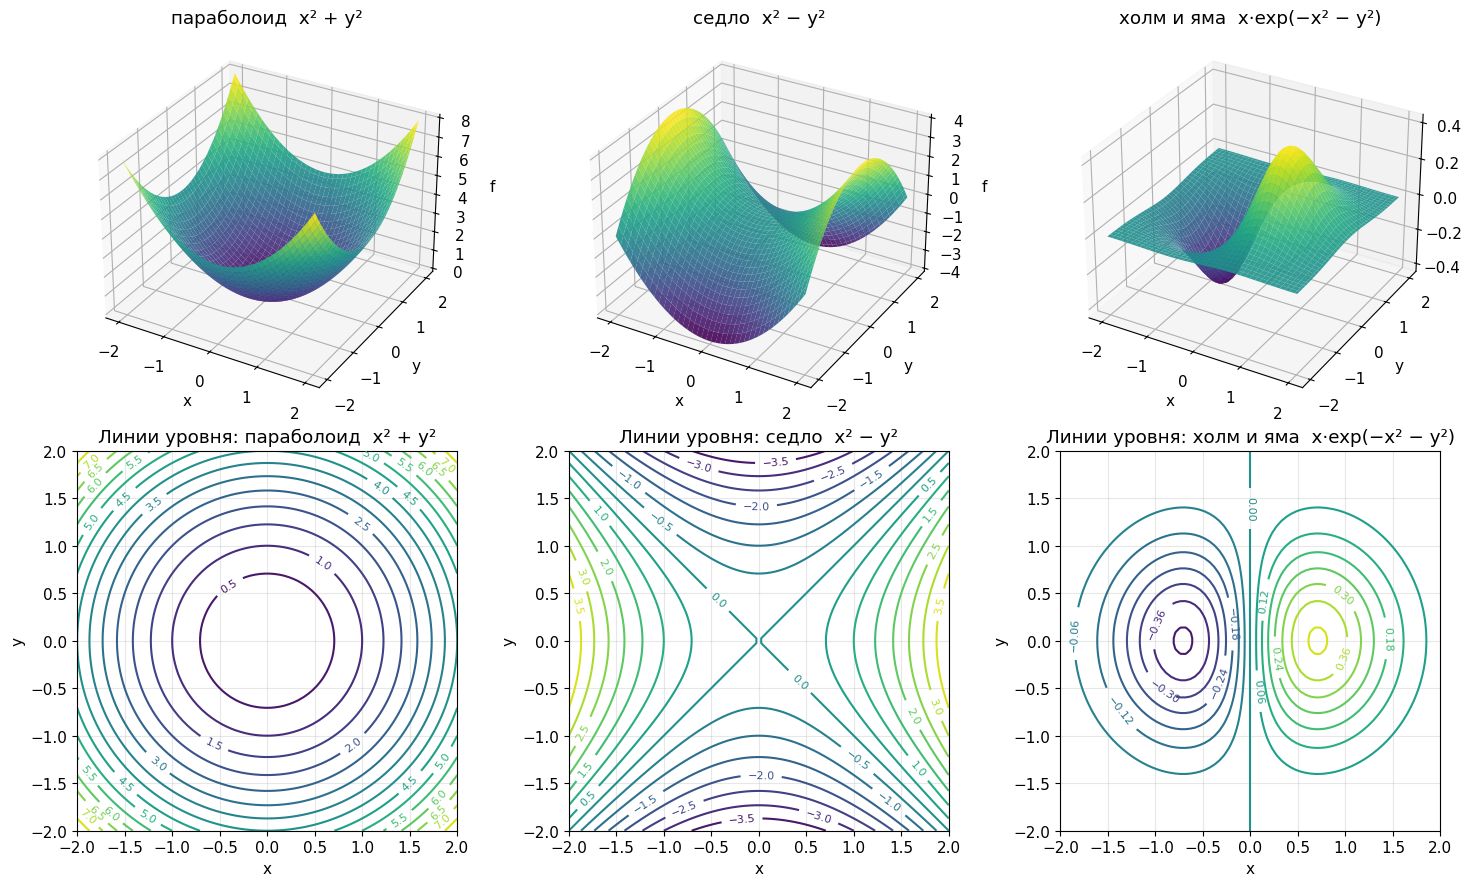

In [2]:
def plot_surface_and_contours(funcs, titles, xlim=(-2, 2), ylim=(-2, 2), n=80, levels=15, points=None,
                              xlabel="x", ylabel="y"):
    """Рисует 3D-поверхность (верхний ряд) и линии уровня (нижний ряд) для списка функций f(X, Y)."""
    xs, ys = np.linspace(*xlim, n), np.linspace(*ylim, n)
    X, Y = np.meshgrid(xs, ys)
    k = len(funcs)
    fig = plt.figure(figsize=(max(5 * k, 7), 9))
    for i, (f, t) in enumerate(zip(funcs, titles)):
        Z = f(X, Y)
        ax = fig.add_subplot(2, k, i + 1, projection="3d")
        ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9, linewidth=0)
        ax.set_title(t); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_zlabel("f")
        ax2 = fig.add_subplot(2, k, k + i + 1)
        cs = ax2.contour(X, Y, Z, levels=levels, cmap="viridis")
        ax2.clabel(cs, inline=True, fontsize=8)
        if points is not None:                       # отметить особые точки (минимум и т. п.)
            for (px, py, lbl) in points[i]:
                ax2.plot(px, py, "r*", markersize=12, label=lbl)
            ax2.legend(loc="upper right")
        ax2.set_title("Линии уровня: " + t); ax2.set_xlabel(xlabel); ax2.set_ylabel(ylabel)
        ax2.set_aspect("equal")                      # равный масштаб осей: форма линий уровня не искажается
    plt.tight_layout(); plt.show()

plot_surface_and_contours(
    funcs=[lambda X, Y: X**2 + Y**2,
           lambda X, Y: X**2 - Y**2,
           lambda X, Y: X * np.exp(-X**2 - Y**2)],
    titles=["параболоид  x² + y²", "седло  x² − y²", "холм и яма  x·exp(−x² − y²)"],
)

**Что мы видим на графике.** У параболоида линии уровня — концентрические окружности, сгущающиеся к краям: чем дальше от минимума, тем круче склон. У седла линии уровня — гиперболы; через центр проходит «крест» $y = \pm x$ нулевого уровня, вдоль оси $x$ от центра значения растут, а вдоль оси $y$ — убывают. У третьей функции два «центра»: холм справа (максимум в точке $(1/\sqrt2, 0)$) и яма слева (минимум в $(-1/\sqrt2, 0)$), а между ними — склон, по которому значения растут от ямы к холму; прямая $x = 0$ — линия нулевого уровня. Запомните эти три картинки: минимум, седло и «несколько экстремумов» — это три типичных сюжета, которые встретятся нам в оптимизации.

### 1.3 Предел и непрерывность (кратко)

Определения предела и непрерывности переносятся с одномерного случая почти дословно — нужно только заменить расстояние $|x - a|$ на длину вектора $\|\mathbf{x} - \mathbf{a}\|$.

> **Определение.** Число $A$ называется *пределом* функции $f$ в точке $\mathbf{a}$ (пишут $\lim_{\mathbf{x}\to\mathbf{a}} f(\mathbf{x}) = A$), если для любого $\varepsilon > 0$ найдётся $\delta > 0$ такое, что $|f(\mathbf{x}) - A| < \varepsilon$ для всех $\mathbf{x}$ из области определения с $0 < \|\mathbf{x} - \mathbf{a}\| < \delta$. Функция *непрерывна* в точке $\mathbf{a}$, если $\lim_{\mathbf{x}\to\mathbf{a}} f(\mathbf{x}) = f(\mathbf{a})$.

Есть одно важное отличие от одномерного случая. На прямой к точке можно подойти только с двух сторон, и на занятии 1 мы говорили про односторонние пределы. На плоскости к точке ведёт бесконечно много путей: по прямым, по параболам, по спиралям. Предел существует только тогда, когда значения функции стремятся к одному и тому же числу *по всем* путям. Поэтому доказать *отсутствие* предела просто: достаточно найти два пути с разными ответами.

> **Пример.** Рассмотрим $f(x, y) = \dfrac{xy}{x^2 + y^2}$ при $(x, y) \ne (0, 0)$. Подойдём к нулю по прямой $y = kx$: $f(x, kx) = \dfrac{k x^2}{x^2 + k^2 x^2} = \dfrac{k}{1 + k^2}$ — значение вообще не зависит от $x$, но зависит от $k$! По оси $x$ ($k = 0$) получаем $0$, по биссектрисе ($k = 1$) — $1/2$. Предел в нуле не существует, и никаким значением $f(0,0)$ функцию нельзя доопределить до непрерывной.

Хорошая новость: все функции, с которыми мы будем работать в ML — многочлены, экспоненты, логарифмы, сигмоиды и их композиции, — непрерывны всюду в своей области определения (сумма, произведение, частное и композиция непрерывных функций непрерывны, как и в одномерном случае). Так что непрерывность функций потерь мы будем считать данностью, а вот их *гладкость* (существование производных) ещё придётся обсуждать — вспомните ReLU из занятия 2.

Проверим пример численно: пойдём к нулю вдоль разных прямых и посмотрим, к чему стремятся значения.

In [3]:
def f_bad(x, y):
    """Функция xy / (x² + y²) — у неё нет предела в нуле."""
    return x * y / (x**2 + y**2)

ts = np.array([1e-1, 1e-2, 1e-3, 1e-4])            # приближаемся к нулю: t -> 0
for k in [0.0, 1.0, -1.0, 2.0]:
    vals = f_bad(ts, k * ts)                         # точки (t, k·t) на прямой y = k·x
    print(f"вдоль прямой y = {k:+.0f}·x: значения {np.round(vals, 4)}   (теория: k/(1+k²) = {k / (1 + k**2):.4f})")
print("Разные прямые — разные пределы, значит, предела в точке (0, 0) не существует.")

вдоль прямой y = +0·x: значения [0. 0. 0. 0.]   (теория: k/(1+k²) = 0.0000)
вдоль прямой y = +1·x: значения [0.5 0.5 0.5 0.5]   (теория: k/(1+k²) = 0.5000)
вдоль прямой y = -1·x: значения [-0.5 -0.5 -0.5 -0.5]   (теория: k/(1+k²) = -0.5000)
вдоль прямой y = +2·x: значения [0.4 0.4 0.4 0.4]   (теория: k/(1+k²) = 0.4000)
Разные прямые — разные пределы, значит, предела в точке (0, 0) не существует.


### 1.4 ML-контекст: MSE как функция от (w, b)

> 💡 **ML-контекст.** Возьмём простейшую модель — линейную регрессию с одним признаком $\hat y = w x + b$ — и данные $(x_i, y_i)$, $i = 1, \dots, n$. Качество модели измеряем среднеквадратичной ошибкой (mean squared error, MSE):
> $$L(w, b) = \frac{1}{n} \sum_{i=1}^{n} \bigl(w x_i + b - y_i\bigr)^2.$$
> Это функция двух переменных, и её можно нарисовать: поверхность над плоскостью параметров $(w, b)$ и линии уровня на этой плоскости. Обучение модели — это спуск по этой поверхности в самую низкую точку. Всё, что мы сегодня узнаем про поверхности, линии уровня и градиент, — про неё.

Раскроем скобки и сгруппируем по степеням $w$ и $b$:
$$L(w, b) = w^2\,\overline{x^2} + b^2 + 2wb\,\overline{x} - 2w\,\overline{xy} - 2b\,\overline{y} + \overline{y^2},$$
где черта означает среднее по выборке: $\overline{x^2} = \frac1n\sum x_i^2$ и т. д. Это многочлен второй степени по $(w, b)$, и его квадратичная часть положительно определена: коэффициенты при квадратах положительны, а её определитель $\overline{x^2} - \overline{x}^2 = \operatorname{Var}(x) > 0$ (признак не постоянный). Поэтому поверхность — *эллиптический параболоид* (чаша), а линии уровня — эллипсы. Обратите внимание на слагаемое $2wb\,\overline{x}$: если признак не центрирован ($\overline{x} \ne 0$), оси эллипсов будут наклонены — параметры $w$ и $b$ «связаны»: изменение $w$ можно частично компенсировать изменением $b$. Сейчас мы это увидим.

Сгенерируем данные по закону $y = 2x + 1 + \text{шум}$ с признаком $x \in [-1, 3]$ (среднее около 1 — специально не центрируем) и нарисуем поверхность и контуры MSE. Точку минимума MSE (её даёт метод наименьших квадратов, `np.polyfit`) отметим звёздочкой; она окажется рядом с истинными параметрами $(w, b) = (2, 1)$, но не точно в них — из-за шума.

минимум MSE: w* = 1.9609, b* = 1.0286,  L(w*, b*) = 0.4033
для сравнения, истинные параметры: w = 2, b = 1,  L(2, 1) = 0.4053


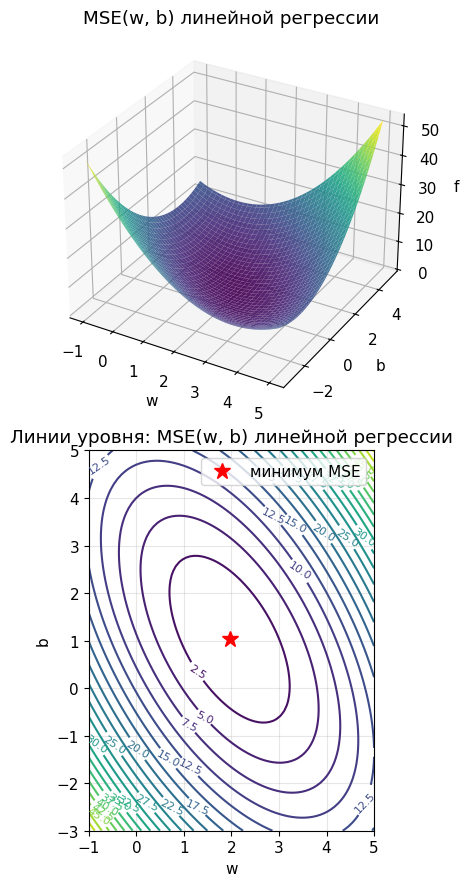

In [4]:
# Данные для одномерной линейной регрессии: y = 2x + 1 + шум
n_pts = 50
x_data = np.random.uniform(-1, 3, n_pts)           # признак НЕ центрирован: среднее ≈ 1
y_data = 2.0 * x_data + 1.0 + np.random.normal(0, 0.7, n_pts)

def mse_wb(W, B):
    """MSE линейной модели y ≈ w·x + b; W и B могут быть числами или сетками одинаковой формы."""
    W, B = np.asarray(W, dtype=float), np.asarray(B, dtype=float)
    pred = W[..., None] * x_data + B[..., None]      # добавляем ось объектов, broadcasting по сетке
    return np.mean((pred - y_data) ** 2, axis=-1)

# Точный минимум MSE (метод наименьших квадратов) — для отметки на графике
w_opt, b_opt = np.polyfit(x_data, y_data, deg=1)
print(f"минимум MSE: w* = {w_opt:.4f}, b* = {b_opt:.4f},  L(w*, b*) = {mse_wb(w_opt, b_opt):.4f}")
print(f"для сравнения, истинные параметры: w = 2, b = 1,  L(2, 1) = {mse_wb(2.0, 1.0):.4f}")

plot_surface_and_contours(
    funcs=[mse_wb], titles=["MSE(w, b) линейной регрессии"],
    xlim=(-1, 5), ylim=(-3, 5), levels=20,
    points=[[(w_opt, b_opt, "минимум MSE")]], xlabel="w", ylabel="b",
)

**Что мы видим на графике.** Поверхность MSE — гладкая чаша с единственным минимумом, а её линии уровня — вложенные эллипсы, вытянутые и наклонённые. Наклон — следствие нецентрированного признака: вдоль «длинной» оси эллипса можно менять $w$ и $b$ одновременно (увеличить наклон, уменьшить сдвиг), почти не меняя ошибку. Вытянутость означает, что в одном направлении функция растёт быстро, а в другом медленно — это тот самый *овраг*, из-за которого градиентный спуск будет двигаться зигзагом. Мы ещё увидим эту карту в блоке 3 (с полем градиентов), а в блоке 4 объясним, чем вытянутость линий уровня грозит оптимизации.

> ❓ **Вопрос аудитории.** Почему линии уровня MSE — эллипсы, а не окружности, как у $x^2 + y^2$? Что должно быть верно про данные, чтобы получились окружности?
>
> <details><summary>Ответ</summary>
>
> Коэффициенты при $w^2$ и $b^2$ в разложении $L(w, b)$ — это $\overline{x^2}$ и $1$, а коэффициент при $wb$ — $2\overline{x}$. Окружности получатся, если $\overline{x^2} = 1$ (признак имеет единичный «масштаб») и $\overline{x} = 0$ (признак центрирован). То есть если признак *стандартизован*: среднее 0, дисперсия 1. Это первый намёк на то, зачем в ML масштабируют признаки, — сегодня мы увидим полное объяснение.
>
> </details>

## 2. Частные производные  <span style="color:gray">⏱ ≈ 20 мин</span>

### 2.1 Определение и вычисление

Как определить производную функции нескольких переменных? На занятии 2 производная была пределом отношения приращения функции к приращению аргумента. Но теперь аргумент — вектор, и «приращение аргумента» может быть направлено куда угодно. Самая простая идея: менять по одной переменной, а остальные держать зафиксированными.

> **Определение.** *Частной производной* (partial derivative) функции $f(x_1, \dots, x_n)$ по переменной $x_i$ в точке $\mathbf{a}$ называется предел
> $$\frac{\partial f}{\partial x_i}(\mathbf{a}) = \lim_{h \to 0} \frac{f(a_1, \dots, a_i + h, \dots, a_n) - f(a_1, \dots, a_i, \dots, a_n)}{h},$$
> если он существует. Обозначения: $\dfrac{\partial f}{\partial x_i}$, $f'_{x_i}$, $f_{x_i}$, $\partial_i f$. Символ $\partial$ читается «дэ круглое».

Обратите внимание на форму записи: в числителе изменилась только $i$-я координата. Это в точности обычная производная функции *одной* переменной $g(t) = f(a_1, \dots, t, \dots, a_n)$ в точке $t = a_i$. Отсюда правило вычисления:

**Чтобы взять частную производную по $x_i$, считайте все остальные переменные константами и дифференцируйте как обычно.** Все правила занятия 2 (линейность, произведение, частное, цепное правило, таблица производных) работают без изменений.

> **Пример.** $f(x, y) = x^2 y + \sin(xy)$.
>
> *По $x$* ($y$ — константа): слагаемое $x^2 y$ даёт $2xy$ (как $(x^2)' \cdot y$); слагаемое $\sin(xy)$ по цепному правилу даёт $\cos(xy)\cdot(xy)'_x = y\cos(xy)$. Итого $\dfrac{\partial f}{\partial x} = 2xy + y\cos(xy)$.
>
> *По $y$* ($x$ — константа): $x^2 y$ даёт $x^2$; $\sin(xy)$ даёт $\cos(xy)\cdot x$. Итого $\dfrac{\partial f}{\partial y} = x^2 + x\cos(xy)$.
>
> В точке $(1, 2)$: $f_x(1, 2) = 4 + 2\cos 2 \approx 3.1677$, $f_y(1, 2) = 1 + \cos 2 \approx 0.5839$. Наклон по $x$ в этой точке примерно в пять раз больше наклона по $y$.

> ⚠️ **Типичная ошибка.** Частная производная $\partial f / \partial x$ — это производная при *независимо* зафиксированном $y$. Если же $y$ сам зависит от $x$, скажем $y = y(x)$, то производная функции $x \mapsto f(x, y(x))$ — другая величина (*полная* производная), и она считается по цепному правилу: $\dfrac{d}{dx} f(x, y(x)) = \dfrac{\partial f}{\partial x} + \dfrac{\partial f}{\partial y}\,y'(x)$. Мы вернёмся к этому в разделе про матрицу Якоби, где эта формула окажется частным случаем многомерного цепного правила.

Проверим ручной расчёт двумя способами: символьно в sympy (`sp.diff` по одной переменной — это и есть «заморозить остальные») и численно, через разностное отношение из определения.

In [5]:
x, y = sp.symbols("x y")
f_sym = x**2 * y + sp.sin(x * y)

fx_sym, fy_sym = sp.diff(f_sym, x), sp.diff(f_sym, y)   # sympy сам «замораживает» другую переменную
print("∂f/∂x =", fx_sym)
print("∂f/∂y =", fy_sym)

# Значения в точке (1, 2)
point = {x: 1, y: 2}
print(f"в точке (1, 2): ∂f/∂x = {float(fx_sym.subs(point)):.4f}, ∂f/∂y = {float(fy_sym.subs(point)):.4f}")

# Численная проверка по определению: центральная разность (занятие 2), «шевелим» одну координату
f_num = sp.lambdify((x, y), f_sym, "numpy")
h = 1e-5
fx_num = (f_num(1 + h, 2) - f_num(1 - h, 2)) / (2 * h)   # y = 2 зафиксирован
fy_num = (f_num(1, 2 + h) - f_num(1, 2 - h)) / (2 * h)   # x = 1 зафиксирован
print(f"численно:       ∂f/∂x ≈ {fx_num:.4f}, ∂f/∂y ≈ {fy_num:.4f}")

∂f/∂x = 2*x*y + y*cos(x*y)
∂f/∂y = x**2 + x*cos(x*y)
в точке (1, 2): ∂f/∂x = 3.1677, ∂f/∂y = 0.5839
численно:       ∂f/∂x ≈ 3.1677, ∂f/∂y ≈ 0.5839


Символьный, численный и ручной ответы совпали. В практике ML вы редко будете дифференцировать руками — это делает autograd, — но понимать, *что именно* он считает, необходимо: каждое число в `.grad` — это такая вот частная производная функции потерь по одному параметру при замороженных остальных.

### 2.2 Геометрический смысл

Возьмём поверхность $z = f(x, y)$ и рассечём её вертикальной плоскостью $y = y_0$. В сечении получится кривая $z = f(x, y_0)$ — график функции одной переменной $x$. Частная производная $\dfrac{\partial f}{\partial x}(x_0, y_0)$ — это угловой коэффициент касательной к этой кривой в точке $x = x_0$, то есть **наклон поверхности в направлении оси $x$**. Аналогично $\dfrac{\partial f}{\partial y}(x_0, y_0)$ — наклон поверхности в направлении оси $y$ (сечение плоскостью $x = x_0$).

Важно понимать: частные производные говорят о наклоне только вдоль двух координатных направлений. Чтобы узнать наклон в произвольном направлении — например, по диагонали, — понадобится градиент; это следующий блок.

Нарисуем поверхность $f(x, y) = x^2 + \tfrac12 y^2$, точку $(x_0, y_0) = (1, 1)$, два сечения через неё и касательные к ним. Здесь $f_x = 2x = 2$ и $f_y = y = 1$: в направлении $x$ поверхность вдвое круче.

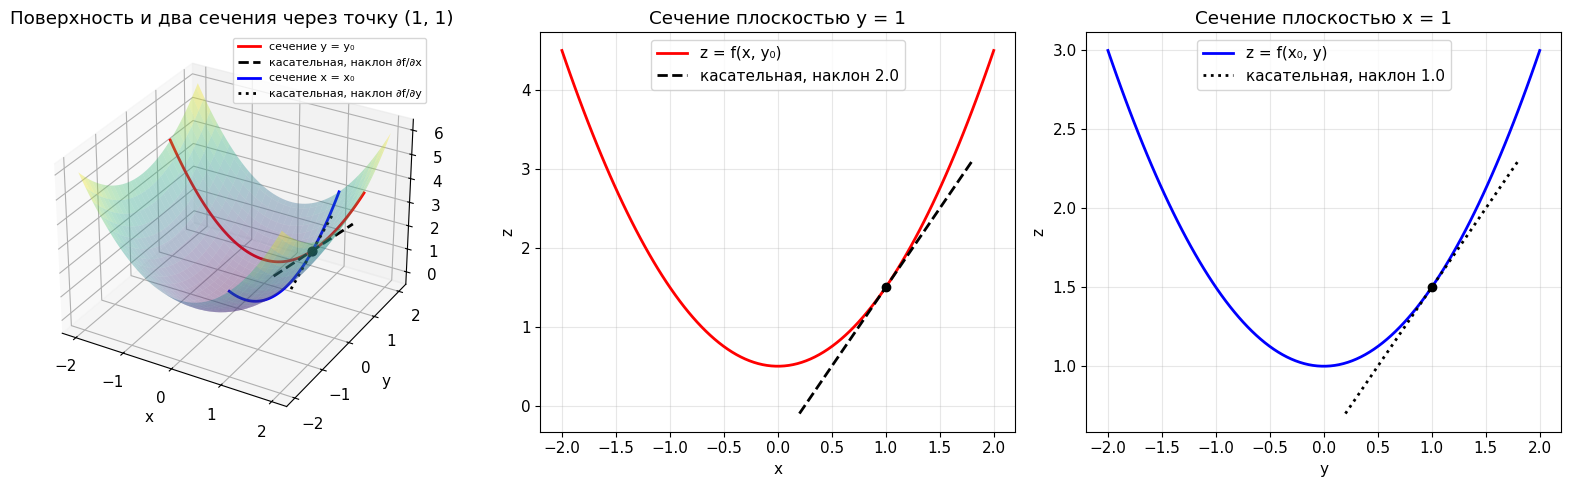

In [6]:
f2 = lambda X, Y: X**2 + 0.5 * Y**2
x0, y0 = 1.0, 1.0
fx0, fy0 = 2 * x0, y0                     # ∂f/∂x = 2x, ∂f/∂y = y
z0 = f2(x0, y0)

xs = np.linspace(-2, 2, 60); X, Y = np.meshgrid(xs, xs)
t = np.linspace(-2, 2, 100); s = np.linspace(-0.8, 0.8, 2)   # параметр вдоль сечения и вдоль касательной

fig = plt.figure(figsize=(16, 5))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.plot_surface(X, Y, f2(X, Y), cmap="viridis", alpha=0.35, linewidth=0)
ax.plot(t, np.full_like(t, y0), f2(t, y0), "r-", lw=2, label="сечение y = y₀")
ax.plot(x0 + s, np.full_like(s, y0), z0 + fx0 * s, "k--", lw=2, label="касательная, наклон ∂f/∂x")
ax.plot(np.full_like(t, x0), t, f2(x0, t), "b-", lw=2, label="сечение x = x₀")
ax.plot(np.full_like(s, x0), y0 + s, z0 + fy0 * s, "k:", lw=2, label="касательная, наклон ∂f/∂y")
ax.scatter([x0], [y0], [z0], color="k", s=40)
ax.set_title("Поверхность и два сечения через точку (1, 1)"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=8)

ax = fig.add_subplot(1, 3, 2)
ax.plot(t, f2(t, y0), "r-", lw=2, label="z = f(x, y₀)")
ax.plot(x0 + s, z0 + fx0 * s, "k--", lw=2, label=f"касательная, наклон {fx0:.1f}")
ax.plot(x0, z0, "ko"); ax.set_title("Сечение плоскостью y = 1"); ax.set_xlabel("x"); ax.set_ylabel("z"); ax.legend()

ax = fig.add_subplot(1, 3, 3)
ax.plot(t, f2(x0, t), "b-", lw=2, label="z = f(x₀, y)")
ax.plot(y0 + s, z0 + fy0 * s, "k:", lw=2, label=f"касательная, наклон {fy0:.1f}")
ax.plot(y0, z0, "ko"); ax.set_title("Сечение плоскостью x = 1"); ax.set_xlabel("y"); ax.set_ylabel("z"); ax.legend()
plt.tight_layout(); plt.show()

**Что мы видим на графике.** Красная кривая — сечение поверхности плоскостью $y = 1$, это парабола $z = x^2 + 0.5$; наклон касательной к ней в точке $x = 1$ равен $2 = f_x(1,1)$. Синяя кривая — сечение плоскостью $x = 1$, парабола $z = 1 + 0.5y^2$ с наклоном $1 = f_y(1,1)$. Частные производные — это буквально «крутизна» поверхности, если идти строго на восток или строго на север.

### 2.3 Частные производные высших порядков. Теорема Шварца

Частная производная $\dfrac{\partial f}{\partial x}$ сама является функцией $n$ переменных, и её тоже можно дифференцировать — по любой переменной. Так возникают частные производные второго порядка. Для функции двух переменных их четыре:
$$\frac{\partial^2 f}{\partial x^2} = \frac{\partial}{\partial x}\left(\frac{\partial f}{\partial x}\right),\qquad \frac{\partial^2 f}{\partial y\,\partial x} = \frac{\partial}{\partial y}\left(\frac{\partial f}{\partial x}\right),\qquad \frac{\partial^2 f}{\partial x\,\partial y} = \frac{\partial}{\partial x}\left(\frac{\partial f}{\partial y}\right),\qquad \frac{\partial^2 f}{\partial y^2} = \frac{\partial}{\partial y}\left(\frac{\partial f}{\partial y}\right).$$
Обозначения короче: $f_{xx}, f_{xy}, f_{yx}, f_{yy}$ (в индексной записи $f_{xy}$ означает «сначала по $x$, потом по $y$»). Производные $f_{xy}$ и $f_{yx}$ называются *смешанными*. Естественный вопрос: важен ли порядок дифференцирования?

> **Теорема (Шварца, о смешанных производных).** Если смешанные производные $f_{xy}$ и $f_{yx}$ существуют в окрестности точки и непрерывны в ней, то они равны: $f_{xy} = f_{yx}$.
>
> *Идея доказательства.* Рассмотрим «второе приращение» $\Delta = f(x+h, y+k) - f(x+h, y) - f(x, y+k) + f(x, y)$. Его можно записать двумя способами: как приращение по $x$ функции $\varphi(x) = f(x, y+k) - f(x, y)$ и как приращение по $y$ функции $\psi(y) = f(x+h, y) - f(x, y)$. Применяя в каждом случае дважды теорему Лагранжа о среднем (занятие 2), получаем $\Delta = hk\, f_{xy}(\xi_1, \eta_1) = hk\, f_{yx}(\xi_2, \eta_2)$ для некоторых промежуточных точек. Делим на $hk$, устремляем $h, k \to 0$ и пользуемся непрерывностью: левая часть стремится к $f_{xy}(x, y)$, правая — к $f_{yx}(x, y)$. Значит, они равны.

Без непрерывности теорема может нарушаться — классический контрпример $f(x, y) = xy\,\dfrac{x^2 - y^2}{x^2 + y^2}$, у которой $f_{xy}(0,0) = -1$, а $f_{yx}(0,0) = 1$, — но для всех «хороших» функций из практики порядок дифференцирования не важен. Это упрощает жизнь: из четырёх вторых производных функции двух переменных различных всего три, а у функции $n$ переменных — $n(n+1)/2$ вместо $n^2$.

Все вторые производные удобно собрать в матрицу:
$$H = \begin{pmatrix} f_{xx} & f_{xy} \\ f_{yx} & f_{yy} \end{pmatrix},\qquad H_{ij} = \frac{\partial^2 f}{\partial x_i\,\partial x_j}.$$
Это *матрица Гессе* (гессиан, Hessian). По теореме Шварца она симметрична. Сегодня она понадобится нам один раз — чтобы объяснить, почему градиентный спуск «зигзагует» в оврагах, — а на занятии 4 гессиан станет главным инструментом проверки, минимум перед нами или седло; на занятии 6 на нём будет построен метод Ньютона.

Проверим теорему Шварца в sympy на нескольких функциях и посмотрим на гессиан.

In [7]:
test_funcs = [x**2 * y + sp.sin(x * y),
              sp.exp(x * y) * sp.cos(y),
              x**3 * y**2 - sp.log(1 + x**2 + y**2)]

for f in test_funcs:
    f_xy = sp.diff(f, x, y)          # сначала по x, потом по y
    f_yx = sp.diff(f, y, x)          # сначала по y, потом по x
    print(f"f = {f}")
    print(f"   f_xy = {sp.simplify(f_xy)}")
    print(f"   f_xy − f_yx упрощается до: {sp.simplify(f_xy - f_yx)}")

print()
print("Гессиан функции x²y + sin(xy):")
H = sp.hessian(test_funcs[0], (x, y))
display(H)
print("Симметричен:", H.equals(H.T))
print("Гессиан в точке (1, 2):", np.round(np.array(H.subs(point), dtype=float), 4).tolist())

f = x**2*y + sin(x*y)


   f_xy = -x*y*sin(x*y) + 2*x + cos(x*y)
   f_xy − f_yx упрощается до: 0
f = exp(x*y)*cos(y)


   f_xy = (x*y*cos(y) - y*sin(y) + cos(y))*exp(x*y)
   f_xy − f_yx упрощается до: 0
f = x**3*y**2 - log(x**2 + y**2 + 1)


   f_xy = 6*x**2*y + 4*x*y/(x**2 + y**2 + 1)**2
   f_xy − f_yx упрощается до: 0

Гессиан функции x²y + sin(xy):


Matrix([
[          -y**2*sin(x*y) + 2*y, -x*y*sin(x*y) + 2*x + cos(x*y)],
[-x*y*sin(x*y) + 2*x + cos(x*y),                 -x**2*sin(x*y)]])

Симметричен: True
Гессиан в точке (1, 2): [[0.3628, -0.2347], [-0.2347, -0.9093]]


Для всех трёх функций разность $f_{xy} - f_{yx}$ упростилась до нуля — порядок дифференцирования не важен, а гессиан симметричен, как и обещает теорема.

> 💡 **ML-контекст.** Частная производная $\partial L / \partial \theta_j$ отвечает на вопрос «насколько изменится ошибка, если чуть-чуть подвинуть *один* параметр $\theta_j$, оставив остальные как есть». Именно эти числа — по одному на каждый параметр — фреймворки вычисляют на каждом шаге обучения: `loss.backward()` в PyTorch заполняет поле `.grad` каждого тензора-параметра ровно частными производными потерь. Вторые производные (гессиан) в глубоком обучении почти не считают: для сети с миллионом параметров это матрица из $10^{12}$ чисел. Но их структура — насколько «овражна» поверхность — определяет, как быстро сойдётся обучение, и мы это увидим в блоке 4.

Набор всех частных производных первого порядка, записанный как вектор, — это градиент, к которому мы переходим.

## 3. Градиент  <span style="color:gray">⏱ ≈ 20 мин</span>

### 3.1 Определение. Дифференцируемость и линейное приближение

> **Определение.** *Градиентом* (gradient) функции $f(x_1, \dots, x_n)$ в точке $\mathbf{x}$ называется вектор из её частных производных:
> $$\nabla f(\mathbf{x}) = \left( \frac{\partial f}{\partial x_1}(\mathbf{x}),\ \frac{\partial f}{\partial x_2}(\mathbf{x}),\ \dots,\ \frac{\partial f}{\partial x_n}(\mathbf{x}) \right).$$
> Символ $\nabla$ читается «набла»; встречается также обозначение $\operatorname{grad} f$.

Градиент — это вектор в том же пространстве $\mathbb{R}^n$, где живёт аргумент: у функции потерь с миллионом параметров градиент — вектор из миллиона чисел, по одному на параметр. Для нашего примера $f(x,y) = x^2 y + \sin(xy)$ получаем $\nabla f = \bigl(2xy + y\cos(xy),\ x^2 + x\cos(xy)\bigr)$, в точке $(1, 2)$ это $\approx (3.168,\ 0.584)$.

Пока это просто способ записи. Содержание у градиента появляется вместе с понятием дифференцируемости. На занятии 2 мы обсуждали, что дифференцируемость функции одной переменной означает возможность приблизить её линейной функцией: $f(x + h) = f(x) + f'(x)\,h + o(h)$. Перенесём это в $\mathbb{R}^n$.

> **Определение.** Функция $f$ называется *дифференцируемой* в точке $\mathbf{x}$, если существует вектор $\mathbf{g} \in \mathbb{R}^n$ такой, что
> $$f(\mathbf{x} + \mathbf{h}) = f(\mathbf{x}) + \langle \mathbf{g}, \mathbf{h} \rangle + o(\|\mathbf{h}\|) \quad \text{при } \mathbf{h} \to \mathbf{0}.$$
> Линейная по $\mathbf{h}$ часть приращения, $df = \langle \mathbf{g}, \mathbf{h} \rangle$, называется *дифференциалом* функции в точке $\mathbf{x}$.

Если такой вектор $\mathbf{g}$ существует, то он обязан совпадать с градиентом: возьмём $\mathbf{h} = (0, \dots, h, \dots, 0)$ (приращение только по $x_i$) — тогда $\langle \mathbf{g}, \mathbf{h}\rangle = g_i h$, и определение превращается в определение частной производной, откуда $g_i = \partial f / \partial x_i$. Итак, $\mathbf{g} = \nabla f(\mathbf{x})$, и мы получаем главную формулу блока — **линейное приближение**:
$$\boxed{\;f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \langle \nabla f(\mathbf{x}), \mathbf{h} \rangle\;}$$
Ошибка этого приближения убывает быстрее, чем $\|\mathbf{h}\|$; для дважды гладких функций — как $\|\mathbf{h}\|^2$ (это многомерный аналог формулы Тейлора с занятия 2). Для функции двух переменных линейное приближение — это уравнение *касательной плоскости* к поверхности в точке $(x_0, y_0)$:
$$z = f(x_0, y_0) + f_x(x_0, y_0)\,(x - x_0) + f_y(x_0, y_0)\,(y - y_0).$$

Тонкость, о которой стоит знать: в отличие от одномерного случая, существование всех частных производных ещё *не гарантирует* дифференцируемости. Пример из блока 1, $xy/(x^2+y^2)$, доопределённый нулём в начале координат: вдоль обеих осей функция тождественно равна нулю, так что обе частные производные в нуле существуют и равны 0, — но функция там даже не непрерывна. Достаточное условие простое: если частные производные существуют и *непрерывны* в окрестности точки, функция в ней дифференцируема. Для гладких функций из ML это выполняется, и дальше мы всегда предполагаем дифференцируемость.

Проверим формулу линейного приближения численно: будем уменьшать сдвиг $\mathbf{h}$ и смотреть, как убывает ошибка $|f(\mathbf{x} + \mathbf{h}) - f(\mathbf{x}) - \langle\nabla f, \mathbf{h}\rangle|$. Если ошибка квадратична по $\|\mathbf{h}\|$, отношение ошибки к $\|\mathbf{h}\|^2$ должно стабилизироваться.

In [8]:
# f(x, y) = x²y + sin(xy) и её градиент — как функции numpy
f_np = lambda x, y: x**2 * y + np.sin(x * y)
grad_np = lambda x, y: np.array([2 * x * y + y * np.cos(x * y), x**2 + x * np.cos(x * y)])

p0 = np.array([1.0, 2.0])
g0 = grad_np(*p0)
direction = np.array([1.0, -1.0]) / np.sqrt(2)      # единичное направление сдвига
print(f"градиент в точке {p0}: {np.round(g0, 4)}")
print(f"{'‖h‖':>8} | {'f(x+h)':>10} | {'лин. прибл.':>12} | {'ошибка':>10} | {'ошибка/‖h‖²':>12}")
for norm_h in [1.0, 0.5, 0.1, 0.05, 0.01, 0.001]:
    h = norm_h * direction
    exact = f_np(*(p0 + h))
    linear = f_np(*p0) + g0 @ h                   # f(x) + <∇f, h>
    err = abs(exact - linear)
    print(f"{norm_h:8.3f} | {exact:10.5f} | {linear:12.5f} | {err:10.2e} | {err / norm_h**2:12.4f}")

градиент в точке [1. 2.]: [3.1677 0.5839]
     ‖h‖ |     f(x+h) |  лин. прибл. |     ошибка |  ошибка/‖h‖²
   1.000 |    4.57206 |      4.73636 |   1.64e-01 |       0.1643
   0.500 |    3.80783 |      3.82283 |   1.50e-02 |       0.0600
   0.100 |    3.09179 |      3.09200 |   2.16e-04 |       0.0216
   0.050 |    3.00060 |      3.00065 |   5.00e-05 |       0.0200
   0.010 |    2.92757 |      2.92757 |   1.93e-06 |       0.0193
   0.001 |    2.91112 |      2.91112 |   1.93e-08 |       0.0193


**Что мы видим в таблице.** При уменьшении $\|\mathbf{h}\|$ в 10 раз ошибка линейного приближения падает примерно в 100 раз, а отношение «ошибка / $\|\mathbf{h}\|^2$» стабилизируется около константы (она равна половине второй производной вдоль направления — многомерный вариант остаточного члена Тейлора). Значит, вблизи точки функция действительно устроена как «своя касательная плоскость плюс маленькая квадратичная поправка».

Нарисуем это: поверхность и касательную плоскость в точке $(1, 2)$. Вблизи точки касания плоскость и поверхность почти неразличимы.

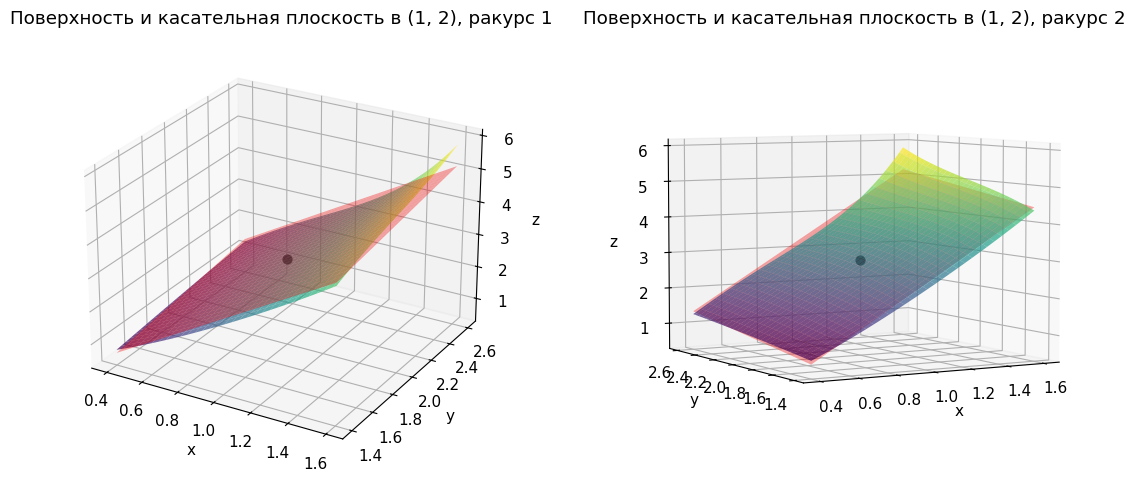

In [9]:
xs = np.linspace(0.4, 1.6, 60); ys = np.linspace(1.4, 2.6, 60)     # окрестность точки (1, 2)
X, Y = np.meshgrid(xs, ys)
Z = f_np(X, Y)
Z_plane = f_np(*p0) + g0[0] * (X - p0[0]) + g0[1] * (Y - p0[1])   # касательная плоскость

fig = plt.figure(figsize=(12, 5))
for i, (elev, azim) in enumerate([(25, -60), (5, -120)]):          # два ракурса
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.7, linewidth=0)
    ax.plot_surface(X, Y, Z_plane, color="red", alpha=0.35, linewidth=0)
    ax.scatter(*p0, f_np(*p0), color="k", s=40)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"Поверхность и касательная плоскость в (1, 2), ракурс {i + 1}")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.tight_layout(); plt.show()

### 3.2 Производная по направлению

Частные производные — это скорости изменения функции вдоль осей координат. А если мы двигаемся из точки $\mathbf{x}$ в произвольном направлении?

> **Определение.** Пусть $\mathbf{u} \in \mathbb{R}^n$ — единичный вектор, $\|\mathbf{u}\| = 1$. *Производной по направлению* $\mathbf{u}$ (directional derivative) функции $f$ в точке $\mathbf{x}$ называется
> $$D_{\mathbf{u}} f(\mathbf{x}) = \lim_{t \to 0} \frac{f(\mathbf{x} + t\mathbf{u}) - f(\mathbf{x})}{t}.$$

Это обычная производная функции одной переменной $t \mapsto f(\mathbf{x} + t\mathbf{u})$ — значений $f$ вдоль прямой, проходящей через $\mathbf{x}$ в направлении $\mathbf{u}$. Частные производные — частный случай: $D_{\mathbf{e}_i} f = \partial f / \partial x_i$, где $\mathbf{e}_i$ — $i$-й базисный вектор (единица на $i$-м месте, нули на остальных).

> **Теорема (формула производной по направлению).** Если $f$ дифференцируема в точке $\mathbf{x}$, то для любого единичного $\mathbf{u}$
> $$D_{\mathbf{u}} f(\mathbf{x}) = \langle \nabla f(\mathbf{x}), \mathbf{u} \rangle = \sum_{i=1}^n \frac{\partial f}{\partial x_i}(\mathbf{x})\, u_i.$$
>
> *Доказательство.* Подставим в определение дифференцируемости $\mathbf{h} = t\mathbf{u}$:
> $$f(\mathbf{x} + t\mathbf{u}) - f(\mathbf{x}) = \langle \nabla f(\mathbf{x}), t\mathbf{u} \rangle + o(\|t\mathbf{u}\|) = t\,\langle \nabla f(\mathbf{x}), \mathbf{u}\rangle + o(t),$$
> так как $\|t\mathbf{u}\| = |t|$. Делим на $t$ и переходим к пределу $t \to 0$: слагаемое $o(t)/t$ стремится к нулю, остаётся $\langle \nabla f(\mathbf{x}), \mathbf{u}\rangle$. $\blacksquare$

Итак, зная всего $n$ чисел — компоненты градиента, — мы знаем скорость роста функции в *любом* из бесконечного числа направлений. Это и есть причина, по которой градиент так важен.

> **Пример.** Для $f(x, y) = x^2 y + \sin(xy)$ в точке $(1, 2)$ градиент $\nabla f \approx (3.168, 0.584)$. Производная по направлению биссектрисы $\mathbf{u} = (1/\sqrt2, 1/\sqrt2)$: $D_{\mathbf{u}} f = (3.168 + 0.584)/\sqrt 2 \approx 2.653$. По направлению $\mathbf{u} = (0, -1)$ (вниз по оси $y$): $D_{\mathbf{u}} f = -0.584$ — функция в эту сторону убывает. По направлению $\mathbf{u} = (-0.584, 3.168)/\|\cdot\| \approx (-0.181, 0.983)$, перпендикулярному градиенту: $D_{\mathbf{u}} f = 0$ — функция в первом приближении не меняется.

Переберём все направления на плоскости: $\mathbf{u}(\varphi) = (\cos\varphi, \sin\varphi)$, $\varphi \in [0, 2\pi)$, — и построим график $D_{\mathbf{u}(\varphi)} f$ от угла $\varphi$. Посчитаем двумя способами: численно по определению и по формуле через градиент.

максимум расхождения формулы и численного расчёта: 7.95e-11
направление градиента: φ* = 10.4°, ‖∇f‖ = 3.2211


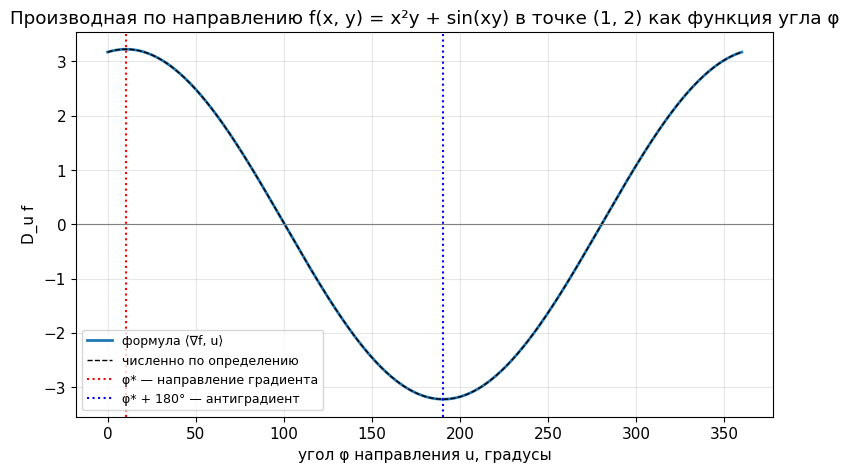

In [10]:
phis = np.linspace(0, 2 * np.pi, 361)
U = np.column_stack([np.cos(phis), np.sin(phis)])            # единичные направления u(φ), форма (361, 2)

D_formula = U @ g0                                          # <∇f, u> для всех направлений сразу
t = 1e-5
D_numeric = np.array([(f_np(*(p0 + t * u)) - f_np(*(p0 - t * u))) / (2 * t) for u in U])  # по определению

phi_star = np.arctan2(g0[1], g0[0])                          # угол самого градиента
print(f"максимум расхождения формулы и численного расчёта: {np.max(np.abs(D_formula - D_numeric)):.2e}")
print(f"направление градиента: φ* = {np.degrees(phi_star):.1f}°, ‖∇f‖ = {np.linalg.norm(g0):.4f}")

plt.figure(figsize=(9, 5))
plt.plot(np.degrees(phis), D_formula, lw=2, label="формула ⟨∇f, u⟩")
plt.plot(np.degrees(phis), D_numeric, "k--", lw=1, label="численно по определению")
plt.axvline(np.degrees(phi_star), color="red", ls=":", label="φ* — направление градиента")
plt.axvline(np.degrees(phi_star) + 180, color="blue", ls=":", label="φ* + 180° — антиградиент")
plt.axhline(0, color="gray", lw=0.8)
plt.title("Производная по направлению f(x, y) = x²y + sin(xy) в точке (1, 2) как функция угла φ")
plt.xlabel("угол φ направления u, градусы"); plt.ylabel("D_u f")
plt.legend(loc="lower left", fontsize=9)                    # слева внизу кривая не проходит — легенда её не закроет
plt.show()

**Что мы видим на графике.** Производная по направлению как функция угла — чистая косинусоида: $D_{\mathbf u} f = \|\nabla f\|\cos(\varphi - \varphi^*)$. Максимум $\|\nabla f\| \approx 3.22$ достигается ровно в направлении градиента (красный пунктир), минимум $-\|\nabla f\|$ — в противоположном направлении (синий пунктир), а нули — при углах $\varphi^* \pm 90^\circ$, то есть перпендикулярно градиенту. Численный расчёт по определению совпадает с формулой. Мы только что увидели теорему, которую сейчас докажем.

### 3.3 Теорема о направлении наискорейшего роста

Теперь можно задать вопрос, ради которого всё затевалось: в каком направлении функция растёт быстрее всего? И в каком — быстрее всего убывает?

> **Теорема.** Пусть $f$ дифференцируема в точке $\mathbf{x}$ и $\nabla f(\mathbf{x}) \ne \mathbf{0}$. Тогда среди всех единичных направлений $\mathbf{u}$:
> 1. производная по направлению максимальна при $\mathbf{u} = \dfrac{\nabla f(\mathbf{x})}{\|\nabla f(\mathbf{x})\|}$ и равна $\|\nabla f(\mathbf{x})\|$ — **градиент указывает направление наискорейшего роста, а его длина — скорость этого роста**;
> 2. производная по направлению минимальна при $\mathbf{u} = -\dfrac{\nabla f(\mathbf{x})}{\|\nabla f(\mathbf{x})\|}$ и равна $-\|\nabla f(\mathbf{x})\|$ — **антиградиент указывает направление наискорейшего убывания**;
> 3. производная по направлению равна нулю тогда и только тогда, когда $\mathbf{u} \perp \nabla f(\mathbf{x})$.
>
> *Доказательство.* По формуле производной по направлению и по определению скалярного произведения через угол $\varphi$ между векторами $\nabla f$ и $\mathbf{u}$:
> $$D_{\mathbf{u}} f = \langle \nabla f, \mathbf{u}\rangle = \|\nabla f\| \cdot \|\mathbf{u}\| \cdot \cos\varphi = \|\nabla f\| \cos\varphi.$$
> Длина градиента в данной точке фиксирована, меняется только $\cos\varphi \in [-1, 1]$. Максимум $\cos\varphi = 1$ достигается при $\varphi = 0$, то есть когда $\mathbf{u}$ сонаправлен с градиентом; минимум $\cos\varphi = -1$ — при $\varphi = \pi$, когда $\mathbf{u}$ направлен против градиента; ноль — при $\varphi = \pm\pi/2$, то есть при $\mathbf{u} \perp \nabla f$. $\blacksquare$

Доказательство — одна строка, но следствие из него — весь современный deep learning: **чтобы уменьшить функцию, нужно сдвинуться против градиента, и это локально лучший из всех возможных способов её уменьшить**. Через десять минут мы превратим это в алгоритм.

### 3.4 Градиент ортогонален линиям уровня

Пункт 3 теоремы имеет красивую геометрическую интерпретацию.

> **Утверждение.** Градиент $\nabla f(\mathbf{x})$ ортогонален линии (поверхности) уровня, проходящей через точку $\mathbf{x}$.
>
> *Идея доказательства.* Пусть $\gamma(t)$ — гладкая кривая, целиком лежащая на линии уровня $f = c$, причём $\gamma(0) = \mathbf{x}$. Тогда $f(\gamma(t)) = c$ для всех $t$: вдоль кривой функция постоянна. Дифференцируем по $t$ — по цепному правилу, которое мы строго сформулируем в разделе 3.5: $\dfrac{d}{dt} f(\gamma(t)) = \langle \nabla f(\gamma(t)), \gamma'(t)\rangle = 0$. При $t = 0$ получаем $\langle \nabla f(\mathbf{x}), \gamma'(0)\rangle = 0$, а $\gamma'(0)$ — касательный вектор к линии уровня в точке $\mathbf{x}$. Значит, градиент перпендикулярен любому касательному направлению.

Интуитивно: вдоль линии уровня функция не меняется, значит, скорость роста в этом направлении нулевая, значит (пункт 3 теоремы), это направление перпендикулярно градиенту. На карте местности: самый крутой подъём — строго поперёк горизонталей. Убедимся в этом на графике: нарисуем линии уровня и *поле градиентов* — в узлах сетки стрелку $\nabla f$ — для трёх функций: квадратичной $x^2 + 10y^2$ (она будет главной героиней блока 4), «холма и ямы» из блока 1 и MSE$(w, b)$.

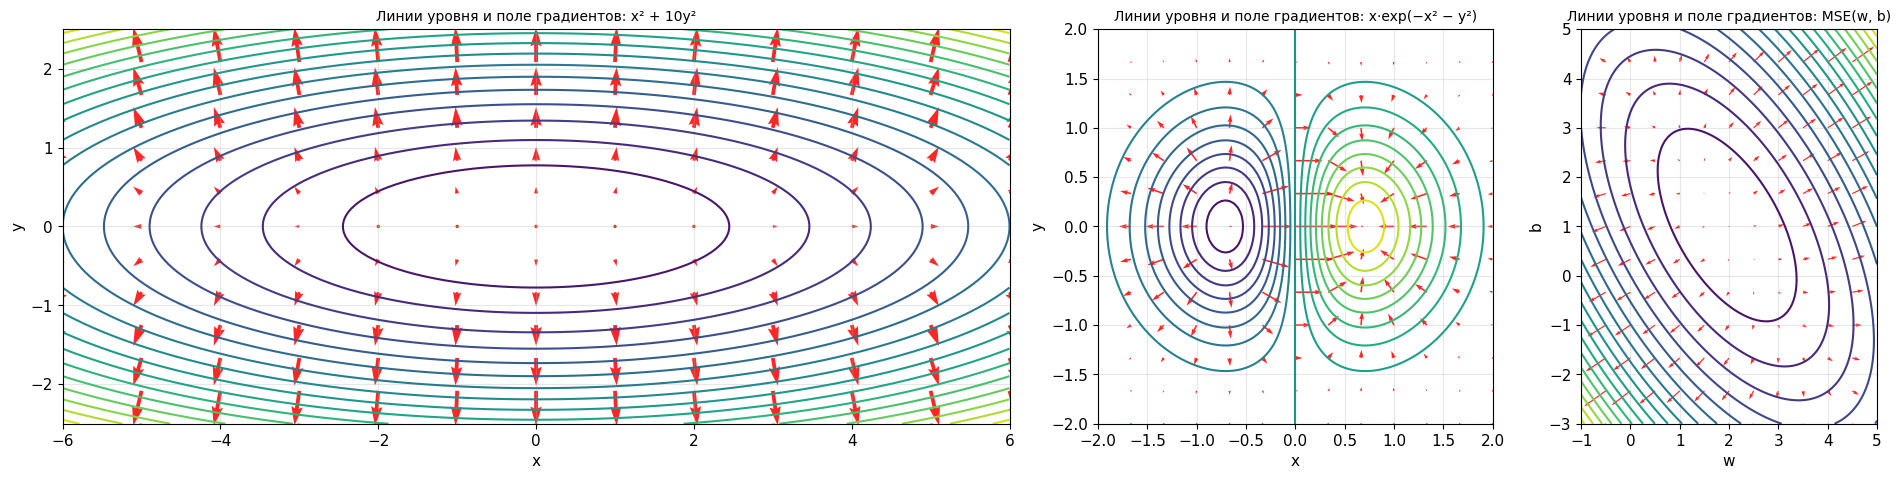

max |⟨∇f, γ'⟩| вдоль линии уровня x² + 10y² = 4.0:  8.88e-16


In [11]:
def mse_grad_wb(W, B):
    """Градиент MSE(w, b) по (w, b) для данных x_data, y_data; W, B — сетки одинаковой формы."""
    r = W[..., None] * x_data + B[..., None] - y_data          # остатки, форма (..., n)
    return 2 * np.mean(r * x_data, axis=-1), 2 * np.mean(r, axis=-1)

panels = [
    dict(title="x² + 10y²", xlim=(-6, 6), ylim=(-2.5, 2.5),
         f=lambda X, Y: X**2 + 10 * Y**2, grad=lambda X, Y: (2 * X, 20 * Y)),
    dict(title="x·exp(−x² − y²)", xlim=(-2, 2), ylim=(-2, 2),
         f=lambda X, Y: X * np.exp(-X**2 - Y**2),
         grad=lambda X, Y: ((1 - 2 * X**2) * np.exp(-X**2 - Y**2), -2 * X * Y * np.exp(-X**2 - Y**2))),
    dict(title="MSE(w, b)", xlim=(-1, 5), ylim=(-3, 5), f=mse_wb, grad=mse_grad_wb),
]

# Ширины панелей подбираем так, чтобы масштаб осей был одинаковым (иначе прямые углы исказятся)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [12 / 5, 1, 6 / 8]})
for ax, pnl in zip(axes, panels):
    xs, ys = np.linspace(*pnl["xlim"], 100), np.linspace(*pnl["ylim"], 100)
    X, Y = np.meshgrid(xs, ys)
    ax.contour(X, Y, pnl["f"](X, Y), levels=18, cmap="viridis")
    xq, yq = np.linspace(*pnl["xlim"], 13), np.linspace(*pnl["ylim"], 13)   # редкая сетка для стрелок
    XQ, YQ = np.meshgrid(xq, yq)
    GX, GY = pnl["grad"](XQ, YQ)
    step = min(xq[1] - xq[0], yq[1] - yq[0])                                # шаг сетки стрелок
    scale = np.max(np.hypot(GX, GY)) / (1.3 * step)                         # самая длинная стрелка ≈ 1.3 шага сетки
    ax.quiver(XQ, YQ, GX, GY, angles="xy", scale_units="xy", scale=scale, color="red", alpha=0.85, width=0.004)
    ax.set_aspect("equal")
    ax.set_title("Линии уровня и поле градиентов: " + pnl["title"], fontsize=10)
    ax.set_xlabel("x" if pnl["title"] != "MSE(w, b)" else "w"); ax.set_ylabel("y" if pnl["title"] != "MSE(w, b)" else "b")
plt.tight_layout(); plt.show()

# Численная проверка ортогональности на эллипсе x² + 10y² = c: параметризуем γ(t) = (√c cos t, √(c/10) sin t)
c, tt = 4.0, np.linspace(0, 2 * np.pi, 200)
gamma = np.column_stack([np.sqrt(c) * np.cos(tt), np.sqrt(c / 10) * np.sin(tt)])
gamma_dot = np.column_stack([-np.sqrt(c) * np.sin(tt), np.sqrt(c / 10) * np.cos(tt)])     # касательный вектор γ'(t)
grad_on_curve = np.column_stack([2 * gamma[:, 0], 20 * gamma[:, 1]])                     # ∇f = (2x, 20y)
print(f"max |⟨∇f, γ'⟩| вдоль линии уровня x² + 10y² = {c}:  {np.max(np.abs(np.sum(grad_on_curve * gamma_dot, axis=1))):.2e}")

**Что мы видим на графике.** Во всех трёх картинах каждая красная стрелка пересекает проходящую через неё линию уровня под прямым углом и смотрит в сторону роста функции: от минимума наружу для чаши, от ямы к холму для второй функции. Численная проверка вдоль эллипса подтверждает: скалярное произведение градиента и касательного вектора равно нулю с машинной точностью.

> ❓ **Вопрос аудитории.** Посмотрите на длины стрелок. Где градиент длиннее — там, где линии уровня идут густо, или там, где редко? Почему?
>
> <details><summary>Ответ</summary>
>
> Там, где густо. Длина градиента — это скорость наискорейшего роста функции. Если линии уровня $f = c$, $f = c + \Delta c$ расположены близко, значит, функция набирает $\Delta c$ на коротком расстоянии — склон крутой, градиент длинный. На плато (линии редкие) градиент короткий; в точке минимума или максимума он нулевой. На карте $x^2 + 10y^2$ стрелки по вертикали заметно длиннее, чем по горизонтали, — овраг круче поперёк, чем вдоль. Именно это создаст проблемы градиентному спуску.
>
> </details>

### 3.5 Матрица Якоби и многомерное цепное правило (обзор)

До сих пор функция возвращала одно число. Но слой нейросети — это отображение вектора в вектор: $F\colon \mathbb{R}^n \to \mathbb{R}^m$, $F(\mathbf{x}) = (F_1(\mathbf{x}), \dots, F_m(\mathbf{x}))$. Что здесь играет роль производной?

> **Определение.** *Матрицей Якоби* (Jacobian) отображения $F\colon \mathbb{R}^n \to \mathbb{R}^m$ в точке $\mathbf{x}$ называется матрица размера $m \times n$ из частных производных всех компонент по всем переменным:
> $$J_F(\mathbf{x}) = \begin{pmatrix} \dfrac{\partial F_1}{\partial x_1} & \cdots & \dfrac{\partial F_1}{\partial x_n} \\ \vdots & \ddots & \vdots \\ \dfrac{\partial F_m}{\partial x_1} & \cdots & \dfrac{\partial F_m}{\partial x_n} \end{pmatrix}.$$
> Строка $i$ — это градиент компоненты $F_i$ (записанный как строка). При $m = 1$ матрица Якоби — одна строка, транспонированный градиент.

Линейное приближение принимает вид $F(\mathbf{x} + \mathbf{h}) \approx F(\mathbf{x}) + J_F(\mathbf{x})\,\mathbf{h}$: производная отображения — это линейное отображение, а матрица Якоби — его матрица.

> **Теорема (многомерное цепное правило).** Если $F\colon \mathbb{R}^n \to \mathbb{R}^m$ дифференцируема в $\mathbf{x}$, а $G\colon \mathbb{R}^m \to \mathbb{R}^k$ дифференцируема в точке $F(\mathbf{x})$, то композиция $G \circ F$ дифференцируема в $\mathbf{x}$ и
> $$J_{G\circ F}(\mathbf{x}) = J_G\bigl(F(\mathbf{x})\bigr)\cdot J_F(\mathbf{x}).$$
> Производная композиции — произведение матриц Якоби (в том порядке, в котором применяются функции, справа налево). Для скалярной внешней функции $g\colon \mathbb{R}^m \to \mathbb{R}$ это даёт градиент композиции:
> $$\nabla (g \circ F)(\mathbf{x}) = J_F(\mathbf{x})^{\top}\, \nabla g\bigl(F(\mathbf{x})\bigr).$$
>
> *Идея доказательства.* Подставим линейное приближение $F$ в линейное приближение $G$: $G(F(\mathbf{x} + \mathbf{h})) \approx G(F(\mathbf{x}) + J_F \mathbf{h}) \approx G(F(\mathbf{x})) + J_G J_F \mathbf{h}$. Композиция линейных отображений — линейное отображение с матрицей-произведением; остаётся аккуратно проверить, что остаточные члены остаются $o(\|\mathbf{h}\|)$.

Одномерное цепное правило $(g(f(x)))' = g'(f(x))\,f'(x)$ — частный случай с матрицами $1 \times 1$. Формула из «типичной ошибки» блока 2, $\frac{d}{dx} f(x, y(x)) = f_x + f_y\, y'(x)$, — тоже частный случай: композиция $x \mapsto (x, y(x)) \mapsto f$, где якобиан первого отображения — столбец $(1, y'(x))^\top$.

> 💡 **ML-контекст: backpropagation.** Нейросеть — это композиция слоёв: $\mathbf{x} \xrightarrow{F_1} \mathbf{h}_1 \xrightarrow{F_2} \mathbf{h}_2 \to \dots \to L$. По цепному правилу градиент потерь по параметрам первого слоя — произведение матриц Якоби всех слоёв. Алгоритм обратного распространения ошибки (backpropagation) — это ровно многомерное цепное правило, применённое *с конца*: сначала берём градиент по выходу, затем умножаем на якобиан последнего слоя, затем предпоследнего и так далее. Идти с конца выгодно: $L$ — скаляр, поэтому на каждом шаге мы умножаем *вектор-строку* на матрицу (vector-Jacobian product), а не перемножаем огромные матрицы Якоби между собой. Именно так работает `loss.backward()` в PyTorch, а `torch.autograd` — это библиотека, которая знает якобианы всех элементарных операций и умеет их перемножать в нужном порядке.

> **Пример (двухслойная сеть).** Пусть $\mathbf{x} \in \mathbb{R}^2$ — вход, $t$ — правильный ответ. Сеть с одним скрытым слоем из трёх нейронов:
> $$\mathbf{z} = W_1 \mathbf{x} + \mathbf{b}_1 \in \mathbb{R}^3,\qquad \mathbf{h} = \sigma(\mathbf{z})\ \text{(поэлементно)},\qquad \hat y = \mathbf{w}_2^{\top}\mathbf{h} + b_2 \in \mathbb{R},\qquad L = (\hat y - t)^2.$$
> Параметры: матрица $W_1$ ($3 \times 2$), векторы $\mathbf{b}_1 \in \mathbb{R}^3$, $\mathbf{w}_2 \in \mathbb{R}^3$ и число $b_2$ — всего 13 чисел. Идём с конца.
> - $\dfrac{\partial L}{\partial \hat y} = 2(\hat y - t)$ — скаляр, обозначим его $\delta_2$.
> - Выходной слой: $\hat y$ линейна по $\mathbf{w}_2$ и $b_2$, поэтому $\nabla_{\mathbf{w}_2} L = \delta_2\, \mathbf{h}$ и $\dfrac{\partial L}{\partial b_2} = \delta_2$. Чтобы идти дальше, нужен градиент по *входу* слоя: $\nabla_{\mathbf{h}} L = \delta_2\, \mathbf{w}_2$ (якобиан отображения $\mathbf{h} \mapsto \mathbf{w}_2^\top \mathbf{h}$ — строка $\mathbf{w}_2^\top$).
> - Сигмоида действует поэлементно, её якобиан — диагональная матрица $\operatorname{diag}(\sigma'(\mathbf{z}))$, а $\sigma' = \sigma(1 - \sigma)$ (занятие 2). Умножение на диагональную матрицу — это поэлементное произведение: $\nabla_{\mathbf{z}} L = \nabla_{\mathbf{h}} L \odot \mathbf{h} \odot (1 - \mathbf{h})$. Обозначим этот вектор $\boldsymbol{\delta}_1 \in \mathbb{R}^3$.
> - Первый слой: $z_i = \sum_j W_{1,ij} x_j + b_{1,i}$, поэтому $\dfrac{\partial L}{\partial W_{1,ij}} = \dfrac{\partial L}{\partial z_i}\cdot\dfrac{\partial z_i}{\partial W_{1,ij}} = \delta_{1,i}\, x_j$, то есть $\nabla_{W_1} L = \boldsymbol{\delta}_1 \mathbf{x}^{\top}$ (внешнее произведение, матрица $3\times 2$), и $\nabla_{\mathbf{b}_1} L = \boldsymbol{\delta}_1$.
>
> Обратите внимание: на каждом шаге мы передаём назад вектор $\boldsymbol\delta$ («ошибку») и умножаем его на якобиан очередного слоя. Ничего, кроме цепного правила, здесь нет.

Сначала проверим цепное правило в sympy на маленьком примере, затем реализуем формулы для двухслойной сети на numpy и сверим с `torch.autograd`.

In [12]:
# Цепное правило в sympy: F: R² -> R², g: R² -> R, ищем градиент композиции g∘F
u, v = sp.symbols("u v")
F = sp.Matrix([x**2 * y, sp.sin(x * y)])          # F(x, y) = (x²y, sin(xy))
g = u + v**2                                      # g(u, v) = u + v²

J_F = F.jacobian([x, y])                          # матрица Якоби 2×2
grad_g = sp.Matrix([sp.diff(g, u), sp.diff(g, v)])
grad_g_at_F = grad_g.subs({u: F[0], v: F[1]})     # ∇g в точке F(x, y)

chain = J_F.T * grad_g_at_F                       # по теореме: ∇(g∘F) = J_F^T · ∇g(F)
composition = g.subs({u: F[0], v: F[1]})          # g(F(x, y)) явно
direct = sp.Matrix([sp.diff(composition, x), sp.diff(composition, y)])

print("Матрица Якоби J_F:"); display(J_F)
print("Разность «по цепному правилу» − «напрямую», после упрощения:", list(sp.simplify(chain - direct)))

Матрица Якоби J_F:


Matrix([
[     2*x*y,       x**2],
[y*cos(x*y), x*cos(x*y)]])

Разность «по цепному правилу» − «напрямую», после упрощения: [0, 0]


In [13]:
import torch

sigmoid_np = lambda z: 1 / (1 + np.exp(-z))
rng = np.random.default_rng(0)
x_in, t_target = rng.normal(size=2), 1.0
W1, b1 = rng.normal(size=(3, 2)), rng.normal(size=3)
w2, b2 = rng.normal(size=3), 0.5

# --- прямой проход (numpy)
z = W1 @ x_in + b1
h = sigmoid_np(z)
y_hat = w2 @ h + b2
L = (y_hat - t_target) ** 2

# --- обратный проход руками: ровно формулы из примера
delta2 = 2 * (y_hat - t_target)             # ∂L/∂ŷ
grad_w2, grad_b2 = delta2 * h, delta2       # выходной слой
grad_h = delta2 * w2                        # градиент по входу выходного слоя
delta1 = grad_h * h * (1 - h)               # через сигмоиду: ⊙ σ'(z)
grad_W1, grad_b1 = np.outer(delta1, x_in), delta1   # первый слой

# --- то же самое через torch.autograd
tW1, tb1 = torch.tensor(W1, requires_grad=True), torch.tensor(b1, requires_grad=True)
tw2, tb2 = torch.tensor(w2, requires_grad=True), torch.tensor(b2, dtype=torch.float64, requires_grad=True)
tx = torch.tensor(x_in)
th = torch.sigmoid(tW1 @ tx + tb1)
tL = (tw2 @ th + tb2 - t_target) ** 2
tL.backward()

print(f"L = {L:.6f} (numpy)  vs  {tL.item():.6f} (torch)")
for name, ours, theirs in [("W1", grad_W1, tW1.grad), ("b1", grad_b1, tb1.grad), ("w2", grad_w2, tw2.grad), ("b2", grad_b2, tb2.grad)]:
    print(f"∇L по {name}: max |numpy − torch| = {np.max(np.abs(ours - theirs.numpy())):.2e}")
print("Градиент по W1 (руками):"); print(np.round(grad_W1, 4))

L = 1.063299 (numpy)  vs  1.063299 (torch)
∇L по W1: max |numpy − torch| = 1.73e-18
∇L по b1: max |numpy − torch| = 1.39e-17
∇L по w2: max |numpy − torch| = 0.00e+00
∇L по b2: max |numpy − torch| = 0.00e+00
Градиент по W1 (руками):
[[-0.0024  0.0025]
 [ 0.0968 -0.1017]
 [ 0.013  -0.0137]]


Ручной backprop и `torch.autograd` дали одинаковые градиенты по всем 13 параметрам с точностью до ошибок округления. Это стоит запомнить: **в autograd нет никакой магии — это многомерное цепное правило, выполненное с конца**. На занятии 5 мы будем обучать сети через `torch.optim` — и там под капотом будет ровно то, что мы только что написали руками.

Подведём итог блока. Градиент — вектор частных производных, и он:
- задаёт линейное приближение $f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \langle \nabla f, \mathbf{h}\rangle$ (касательную плоскость);
- через скалярное произведение даёт скорость роста в любом направлении: $D_{\mathbf u} f = \langle \nabla f, \mathbf u\rangle = \|\nabla f\|\cos\varphi$;
- указывает направление наискорейшего роста, а антиградиент — наискорейшего убывания;
- ортогонален линиям уровня;
- обобщается до матрицы Якоби, а цепное правило для якобианов — это backpropagation.

После перерыва мы применим всё это к поиску минимума.

## ☕ Перерыв 10 минут

После перерыва — градиентный спуск: превращаем теорему о направлении наискорейшего убывания в алгоритм, смотрим, как он ведёт себя на разных функциях и при разных шагах, и обучаем им линейную и логистическую регрессию с нуля.

## 4. Градиентный спуск  <span style="color:gray">⏱ ≈ 20 мин</span>

### 4.1 Алгоритм, шаг и критерии остановки

Соберём вместе всё, что узнали. Мы хотим найти минимум функции $f\colon \mathbb{R}^n \to \mathbb{R}$. Линейное приближение говорит: $f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \langle \nabla f(\mathbf{x}), \mathbf{h}\rangle$. Чтобы значение уменьшилось, нужно $\langle \nabla f, \mathbf{h}\rangle < 0$, а самое сильное уменьшение при фиксированной длине шага даёт антиградиент (теорема из блока 3). Возьмём $\mathbf{h} = -\eta\,\nabla f(\mathbf{x})$ с небольшим $\eta > 0$: тогда
$$f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) - \eta\|\nabla f(\mathbf{x})\|^2 < f(\mathbf{x}),$$
то есть функция уменьшилась — если $\eta$ достаточно мало, чтобы линейное приближение было верным. Повторяем из новой точки.

> **Определение (градиентный спуск, gradient descent, GD).** Выбираем начальную точку $\mathbf{x}_0$ и шаг $\eta > 0$ (learning rate, скорость обучения) и итерируем:
> $$\mathbf{x}_{k+1} = \mathbf{x}_k - \eta\, \nabla f(\mathbf{x}_k),\qquad k = 0, 1, 2, \dots$$

Псевдокод:

```
вход: ∇f, x0, η, ε, tol, max_iter
x ← x0
для k = 0, 1, …, max_iter − 1:
    g ← ∇f(x)
    если ‖g‖ < ε:            остановиться      # критерий 1: градиент почти нулевой
    x_new ← x − η·g
    если |f(x_new) − f(x)| < tol: остановиться  # критерий 2: функция перестала меняться
    x ← x_new
выход: x                                       # критерий 3: исчерпан лимит итераций
```

**Критерии остановки.** Их три, и обычно используют все сразу:
1. $\|\nabla f(\mathbf{x}_k)\| < \varepsilon$ — мы близко к *стационарной точке*, где градиент нулевой (для выпуклых функций это минимум — докажем на занятии 4);
2. $|f(\mathbf{x}_{k+1}) - f(\mathbf{x}_k)| < \text{tol}$ или $\|\mathbf{x}_{k+1} - \mathbf{x}_k\| < \text{tol}$ — прогресс прекратился;
3. $k = \text{max\_iter}$ — страховка от бесконечного цикла; в обучении нейросетей эту роль играет число эпох.

**Выбор шага $\eta$** — главный гиперпараметр. Слишком маленький шаг — алгоритм ползёт и не успевает дойти до минимума за отведённые итерации. Слишком большой — линейное приближение перестаёт работать: мы «перепрыгиваем» через минимум, функция начинает *расти*, и метод расходится. На занятии 2 мы это видели в одномерном случае; сейчас увидим в двумерном, где добавляется новый эффект — зигзаг, — а на занятии 5 разберём теорию (условие $\eta < 2/L$) и методы, которые подбирают шаг адаптивно (momentum, Adam, расписания).

Реализуем алгоритм в общем виде — функция принимает градиент, начальную точку и шаг, а возвращает всю траекторию (она понадобится для рисования) и причину остановки.

In [14]:
def gradient_descent(grad, x0, eta, n_iter=1000, eps=1e-6, f=None, tol=1e-12, max_norm=1e6):
    """Градиентный спуск с тремя критериями остановки; возвращает траекторию (массив точек) и причину остановки."""
    x = np.array(x0, dtype=float)
    traj = [x.copy()]
    for k in range(n_iter):
        g = grad(x)
        if np.linalg.norm(g) < eps:                       # критерий 1: градиент почти нулевой
            return np.array(traj), f"‖∇f‖ < ε на итерации {k}"
        x_new = x - eta * g                               # шаг против градиента
        if np.linalg.norm(x_new) > max_norm:              # защита: точка улетела — метод расходится
            traj.append(x_new.copy())
            return np.array(traj), f"расходимость на итерации {k}"
        if f is not None and abs(f(x_new) - f(x)) < tol:  # критерий 2: функция не меняется
            traj.append(x_new.copy())
            return np.array(traj), f"|Δf| < tol на итерации {k}"
        x = x_new
        traj.append(x.copy())
    return np.array(traj), f"лимит {n_iter} итераций"    # критерий 3

# Быстрая проверка на параболоиде x² + y²: градиент (2x, 2y), при η = 0.5 минимум находится за один шаг
traj, reason = gradient_descent(lambda p: 2 * p, x0=[3.0, -4.0], eta=0.5)
print("x² + y², η = 0.5:", reason, "| конечная точка:", np.round(traj[-1], 6))

x² + y², η = 0.5: ‖∇f‖ < ε на итерации 1 | конечная точка: [0. 0.]


### 4.2 Демонстрация на квадратичной функции

Возьмём $f(x, y) = x^2 + 10 y^2$. Минимум очевиден — точка $(0, 0)$, но функция интересна тем, что по оси $y$ она в 10 раз «круче», чем по $x$: линии уровня — эллипсы, вытянутые вдоль $x$ (овраг). Градиент: $\nabla f = (2x,\ 20y)$. Шаг градиентного спуска распадается на две независимые одномерные итерации:
$$x_{k+1} = x_k - 2\eta x_k = (1 - 2\eta)\, x_k,\qquad y_{k+1} = y_k - 20\eta y_k = (1 - 20\eta)\, y_k.$$
Это геометрические прогрессии! Значит, $x_k = (1 - 2\eta)^k x_0$ и $y_k = (1 - 20\eta)^k y_0$, и мы можем всё предсказать заранее:
- сходимость по $y$ требует $|1 - 20\eta| < 1$, то есть $0 < \eta < 0.1$; по $x$ — $|1 - 2\eta| < 1$, то есть $\eta < 1$. Итого метод сходится при $\eta < 0.1$: **допустимый шаг диктует самое крутое направление**;
- при $\eta > 0.05$ множитель $1 - 20\eta$ отрицателен: координата $y$ на каждом шаге меняет знак — траектория «зигзагует», перепрыгивая через дно оврага;
- при $\eta = 0.02$ множитель по $x$ равен $0.96$ — за 100 итераций $x$ уменьшится лишь в $0.96^{-100} \approx 59$ раз, тогда как $y$ с множителем $0.6$ уже за 30 шагов практически обнулится: **скорость сходимости диктует самое пологое направление**;
- при $\eta > 0.1$ — расходимость: $|y_k| \to \infty$.

Проверим эти предсказания: запустим спуск из точки $(-9, 3)$ при четырёх значениях $\eta$ и нарисуем траектории поверх линий уровня.

η = 0.02: лимит 100 итераций; конечная точка [-0.1518  0.    ], f = 2.305e-02
η = 0.06: лимит 100 итераций; конечная точка [-0.  0.], f = 6.383e-10


η = 0.095: лимит 100 итераций; конечная точка [-0.      0.0001], f = 6.350e-08
η = 0.105: расходимость на итерации 60; конечная точка [   -0.     -1004.7894], f = 1.010e+07


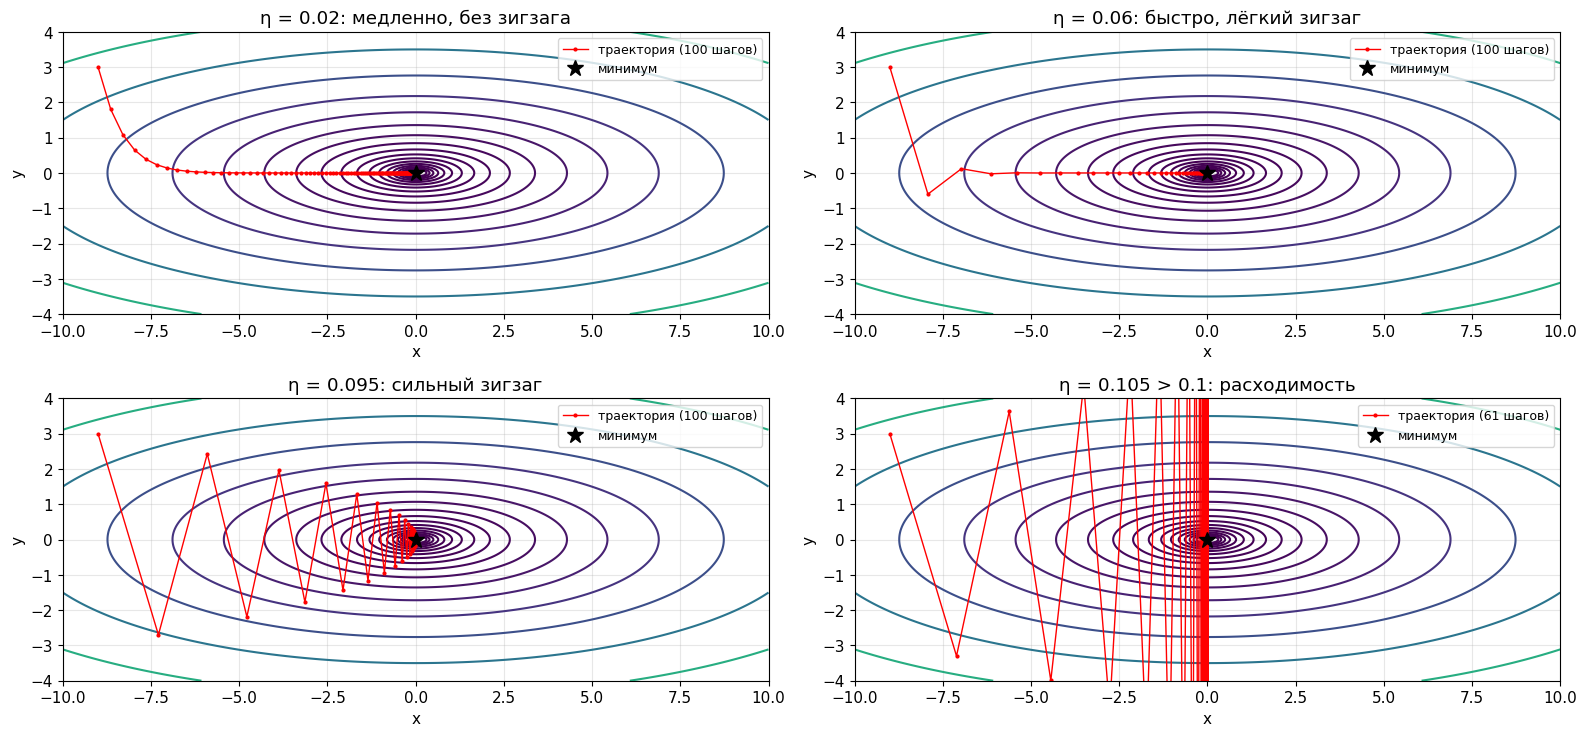

In [15]:
f_quad = lambda p: p[0]**2 + 10 * p[1]**2
grad_quad = lambda p: np.array([2 * p[0], 20 * p[1]])
x_start = [-9.0, 3.0]

xs, ys = np.linspace(-10, 10, 200), np.linspace(-4, 4, 200)
X, Y = np.meshgrid(xs, ys)
Z = X**2 + 10 * Y**2

etas = [0.02, 0.06, 0.095, 0.105]
titles = ["η = 0.02: медленно, без зигзага", "η = 0.06: быстро, лёгкий зигзаг",
          "η = 0.095: сильный зигзаг", "η = 0.105 > 0.1: расходимость"]
results = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
for ax, eta, ttl in zip(axes.ravel(), etas, titles):
    traj, reason = gradient_descent(grad_quad, x_start, eta, n_iter=100, eps=1e-6, max_norm=1e3)
    results[eta] = traj
    ax.contour(X, Y, Z, levels=np.logspace(-1, 2.5, 18), cmap="viridis")
    ax.plot(traj[:, 0], traj[:, 1], "r.-", lw=1, markersize=4, label=f"траектория ({len(traj) - 1} шагов)")
    ax.plot(0, 0, "k*", markersize=12, label="минимум")
    ax.set_xlim(-10, 10); ax.set_ylim(-4, 4); ax.set_aspect("equal")     # равный масштаб: эллипсы «настоящие»
    ax.set_title(ttl); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper right", fontsize=9)
    print(f"η = {eta}: {reason}; конечная точка {np.round(traj[-1], 4)}, f = {f_quad(traj[-1]):.3e}")
plt.tight_layout(); plt.show()

**Что мы видим на графике.** Всё, как предсказано. При $\eta = 0.02$ траектория гладкая: спуск сначала быстро «падает» на дно оврага (по $y$), а затем медленно ползёт вдоль него к минимуму и за 100 шагов не доходит. При $\eta = 0.06$ — хороший компромисс: небольшой зигзаг по $y$ и уверенное движение по $x$. При $\eta = 0.095$ множитель $1 - 20\eta = -0.9$: точка на каждом шаге перескакивает через дно оврага, зигзаг занимает почти всю картинку, и по $y$ метод сходится медленно, хотя по $x$ ($0.81$ за шаг) — быстрее всех. При $\eta = 0.105$ множитель $-1.1$: амплитуда зигзага растёт, и точка вылетает за границы графика — расходимость. Посмотрим на те же запуски через значение функции.

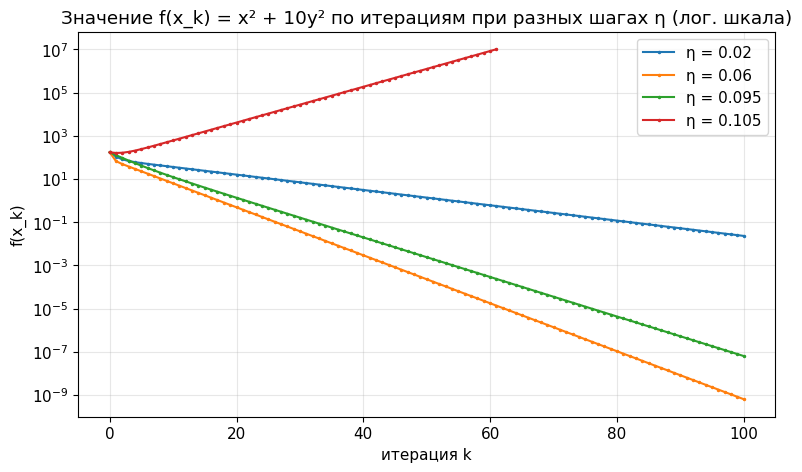

In [16]:
plt.figure(figsize=(9, 5))
for eta, traj in results.items():
    vals = np.array([f_quad(p) for p in traj])
    plt.semilogy(vals, ".-", markersize=3, label=f"η = {eta}")
plt.title("Значение f(x_k) = x² + 10y² по итерациям при разных шагах η (лог. шкала)")
plt.xlabel("итерация k"); plt.ylabel("f(x_k)"); plt.legend(); plt.show()

**Что мы видим на графике.** В логарифмической шкале сходимость геометрической прогрессии — прямая линия, и её наклон — скорость сходимости. У $\eta = 0.06$ и $\eta = 0.095$ наклоны на «хвосте» определяются самым медленным множителем ($0.88$ и $0.9$ соответственно), у $\eta = 0.02$ — множителем $0.96$, потому линия самая пологая. Расходящийся запуск ($\eta = 0.105$) — растущая прямая. Обратите внимание: при $\eta = 0.095$ спуск идёт *медленнее*, чем при $\eta = 0.06$, хотя шаг больше, — зигзаг поперёк оврага «съедает» весь выигрыш от крупного шага.

> ❓ **Вопрос аудитории.** Какой шаг $\eta$ будет наилучшим для $f(x, y) = x^2 + 10y^2$ — дающим самую быструю сходимость сразу по обеим координатам?
>
> <details><summary>Ответ</summary>
>
> Скорость определяется худшим из двух множителей: $\max(|1 - 2\eta|, |1 - 20\eta|)$. Пока $\eta$ мало, худший — $|1 - 2\eta|$ (медленное $x$), и он убывает с ростом $\eta$; после некоторого момента худшим становится $|1 - 20\eta|$ (зигзаг по $y$), и он растёт. Оптимум — там, где они равны: $1 - 2\eta = 20\eta - 1$, откуда $\eta^* = 2/22 = 1/11 \approx 0.0909$, множитель $9/11 \approx 0.818$. В общем виде $\eta^* = 2/(\lambda_{\min} + \lambda_{\max})$, а оптимальный множитель равен $(\kappa - 1)/(\kappa + 1)$, где $\kappa = \lambda_{\max}/\lambda_{\min}$. При $\kappa = 10$ это $0.818$ — за 50 итераций ошибка уменьшится всего в $0.818^{-50} \approx 23\,000$ раз, а при $\kappa = 1$ (окружности) — за один шаг.
>
> </details>

### 4.3 Овраги и число обусловленности

Обобщим наблюдение. Любая квадратичная функция с минимумом в нуле записывается как $f(\mathbf{x}) = \frac12 \mathbf{x}^{\top} H \mathbf{x}$, где $H$ — симметричная положительно определённая матрица (её гессиан, он же матрица вторых производных из блока 2). Для нашей $f = x^2 + 10y^2$ имеем $H = \operatorname{diag}(2, 20)$. Градиент $\nabla f = H\mathbf{x}$, и шаг GD — линейное отображение: $\mathbf{x}_{k+1} = (I - \eta H)\,\mathbf{x}_k$.

Пусть $\lambda_{\min} = \lambda_1 \le \dots \le \lambda_n = \lambda_{\max}$ — собственные числа $H$ (для диагональной матрицы это её диагональ; для произвольной симметричной — «кривизны» вдоль главных осей эллипсов-линий уровня). В базисе собственных векторов итерация распадается на независимые прогрессии с множителями $1 - \eta\lambda_i$ — ровно как выше. Отсюда два вывода.

- **Условие сходимости:** $|1 - \eta\lambda_i| < 1$ для всех $i$, то есть $\eta < 2 / \lambda_{\max}$. Шаг ограничен самым крутым направлением.
- **Скорость сходимости** определяется самым пологим направлением: при безопасном $\eta \approx 1/\lambda_{\max}$ множитель вдоль пологой оси равен $1 - \lambda_{\min}/\lambda_{\max} = 1 - 1/\kappa$, где
$$\kappa = \frac{\lambda_{\max}}{\lambda_{\min}}$$
— **число обусловленности** (condition number) матрицы $H$. Чтобы уменьшить ошибку в $1/\varepsilon$ раз, нужно $k$ итераций с $(1 - 1/\kappa)^k \approx \varepsilon$, то есть $k \approx \kappa \ln(1/\varepsilon)$: **число итераций растёт линейно по $\kappa$**.

Геометрически $\kappa$ — это квадрат отношения полуосей эллипсов-линий уровня. При $\kappa = 1$ линии уровня — окружности, антиградиент смотрит точно в минимум, и GD сходится за один шаг при $\eta = 1/\lambda$. При $\kappa \gg 1$ линии уровня — узкие вытянутые эллипсы, овраг. Антиградиент перпендикулярен линии уровня и потому смотрит почти *поперёк* оврага, а не вдоль него к минимуму: алгоритм вынужден делать мелкие шаги (иначе разлетится поперёк) и очень долго идёт вдоль дна. Это и есть зигзаг.

Проверим на семействе функций $f_\kappa(x, y) = x^2 + \kappa y^2$, у которых $H = \operatorname{diag}(2, 2\kappa)$ и число обусловленности равно $\kappa$. Шаг для каждой возьмём одинаковым в относительном смысле — $\eta = 1.8/\lambda_{\max}$, то есть 90 % от границы устойчивости $2/\lambda_{\max}$ — и посчитаем, сколько итераций нужно, чтобы дойти до $\|\nabla f\| < 10^{-6}$.

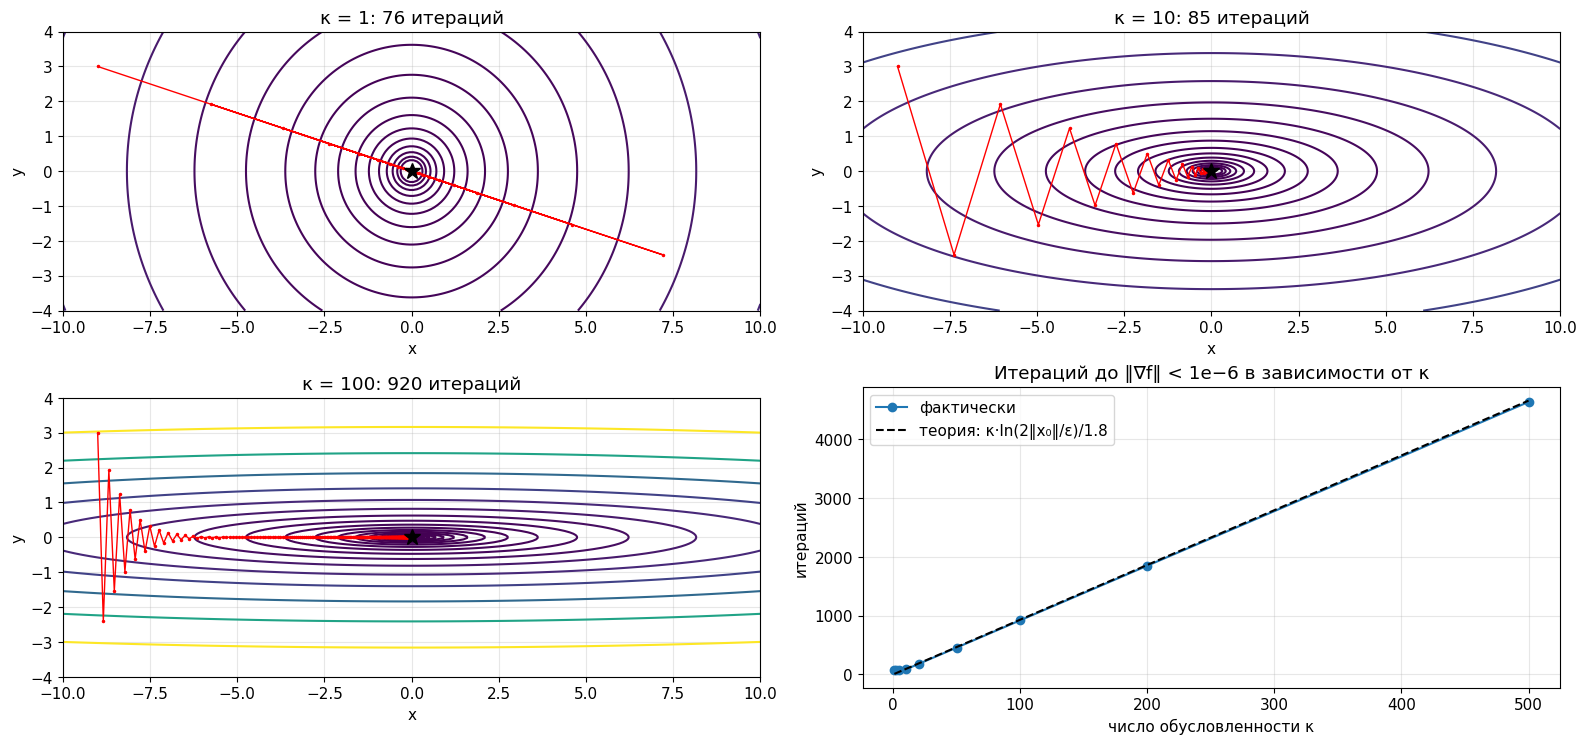

κ:         [1, 2, 5, 10, 20, 50, 100, 200, 500]
итераций:  [76, 74, 78, 85, 178, 456, 920, 1848, 4633]
теория:    [9, 19, 47, 93, 186, 466, 931, 1862, 4655]


In [17]:
def run_gd_kappa(kappa, x0=(-9.0, 3.0), rel_eta=1.8, n_iter=200000):
    """GD на f = x² + κy² с шагом η = rel_eta / λ_max; возвращает траекторию и число итераций."""
    grad = lambda p: np.array([2 * p[0], 2 * kappa * p[1]])
    eta = rel_eta / (2 * kappa)                       # λ_max = 2κ
    traj, reason = gradient_descent(grad, x0, eta, n_iter=n_iter, eps=1e-6)
    return traj, len(traj) - 1

kappas_plot = [1, 10, 100]
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
axes = axes.ravel()
for ax, kappa in zip(axes[:3], kappas_plot):
    traj, n_it = run_gd_kappa(kappa)
    xs, ys = np.linspace(-10, 10, 200), np.linspace(-4, 4, 200)
    X, Y = np.meshgrid(xs, ys)
    ax.contour(X, Y, X**2 + kappa * Y**2, levels=np.logspace(-1, 3, 18), cmap="viridis")
    ax.plot(traj[:, 0], traj[:, 1], "r.-", lw=1, markersize=3)
    ax.plot(0, 0, "k*", markersize=12)
    ax.set_xlim(-10, 10); ax.set_ylim(-4, 4); ax.set_aspect("equal")
    ax.set_title(f"κ = {kappa}: {n_it} итераций"); ax.set_xlabel("x"); ax.set_ylabel("y")

kappas_scan = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500])
iters = [run_gd_kappa(k)[1] for k in kappas_scan]
# Теория: вдоль пологой оси множитель 1 − 1.8/κ, нужно k ≈ κ·ln(2‖x0‖/ε)/1.8 итераций (асимптотика при больших κ)
theory = kappas_scan * np.log(2 * np.linalg.norm([-9.0, 3.0]) / 1e-6) / 1.8
axes[3].plot(kappas_scan, iters, "o-", label="фактически")
axes[3].plot(kappas_scan, theory, "k--", label="теория: κ·ln(2‖x₀‖/ε)/1.8")
axes[3].set_title("Итераций до ‖∇f‖ < 1e−6 в зависимости от κ"); axes[3].set_xlabel("число обусловленности κ"); axes[3].set_ylabel("итераций"); axes[3].legend()
plt.tight_layout(); plt.show()
print("κ:        ", kappas_scan.tolist())
print("итераций: ", iters)
print("теория:   ", np.round(theory).astype(int).tolist())

**Что мы видим на графике.** При $\kappa = 1$ (окружности) оба множителя равны $1 - 1.8 = -0.8$: точка на каждом шаге перепрыгивает через минимум на противоположную сторону, так что траектория выглядит как отрезок через центр, а длина прыжков убывает в геометрической прогрессии — за несколько десятков итераций точка в минимуме (при «идеальном» шаге $1/\lambda_{\max}$ хватило бы одного шага). При $\kappa = 10$ зигзаг поперёк оврага гасится за те же десятки итераций, но дальше точка медленно ползёт вдоль дна — всего около сотни итераций. При $\kappa = 100$ картина та же, но итераций уже около тысячи. Правый график подтверждает теорию: начиная с $\kappa \approx 10$ число итераций растёт *линейно* по $\kappa$ (пунктир — асимптотика $\kappa \ln(2\|\mathbf{x}_0\|/\varepsilon)/1.8$), а при малых $\kappa$ выходит на постоянный уровень около 75 — это «плата за зигзаг» с множителем $0.8$, не зависящая от $\kappa$. Для функций потерь реальных моделей $\kappa$ бывает $10^4$–$10^6$ — и вот почему «чистый» градиентный спуск в таком виде почти никто не использует; на занятии 5 мы разберём, как с этим борются (momentum, адаптивные методы), а на занятии 6 — метод Ньютона, который «выпрямляет» овраг.

> 💡 **ML-контекст: масштабирование признаков.** Для линейной регрессии функция потерь — квадратичная, и её гессиан равен $H = \frac{2}{n} X^{\top} X$ (мы выведем это в следующем блоке). Если один признак измеряется в единицах, а другой — в тысячах (доля от 0 до 1 и доход в рублях), диагональные элементы $X^{\top}X$ различаются на порядки, $\kappa$ огромно — и градиентный спуск зигзагует именно так, как мы только что видели. **Стандартизация признаков** (вычесть среднее, поделить на стандартное отклонение) делает все диагональные элементы матрицы $\frac1n X^\top X$ равными единице, и $\kappa$ определяется только корреляциями между признаками. Это математическая причина, по которой `StandardScaler` стоит первым шагом почти в любом пайплайне с градиентным обучением — от линейных моделей до нейросетей (там ту же роль играют BatchNorm и LayerNorm). В следующем блоке мы измерим этот эффект.

> ⚠️ **Типичная ошибка.** Подобрать шаг $\eta$ на одном датасете и перенести его на другой, где признаки в другом масштабе. Допустимый шаг $\eta < 2/\lambda_{\max}$ зависит от масштаба данных: домножили признак на 10 — соответствующее собственное число гессиана выросло в 100 раз, и прежний шаг ведёт к расходимости. Именно поэтому после стандартизации «универсальные» значения вроде $\eta = 0.01$–$0.1$ обычно работают, а без неё — нет.

## 5. Практика: линейная регрессия  <span style="color:gray">⏱ ≈ 20 мин</span>

### 5.1 MSE в матричной форме и её градиент

Переходим от учебных функций к настоящей модели. Пусть у нас $n$ объектов и $d$ признаков. Соберём признаки в матрицу $X$ размера $n \times (d+1)$: строка $i$ — это объект $\mathbf{x}_i^{\top} = (1, x_{i1}, \dots, x_{id})$, где первая единица — «признак-константа» для свободного члена. Тогда вектор параметров $\mathbf{w} = (w_0, w_1, \dots, w_d)^{\top}$ включает свободный член $b = w_0$, а предсказания для всех объектов сразу — это одно матричное умножение $\hat{\mathbf{y}} = X\mathbf{w}$.

> **Определение.** Функция потерь линейной регрессии (MSE) в матричной форме:
> $$L(\mathbf{w}) = \frac{1}{n}\sum_{i=1}^n (\mathbf{x}_i^{\top}\mathbf{w} - y_i)^2 = \frac{1}{n}\|X\mathbf{w} - \mathbf{y}\|^2 = \frac{1}{n} (X\mathbf{w} - \mathbf{y})^{\top}(X\mathbf{w} - \mathbf{y}).$$

Найдём градиент двумя способами — покомпонентно и в матричном виде; полезно уметь оба.

**Способ 1: по компонентам.** $L$ — сумма квадратов, и каждый квадрат зависит от $w_j$ через $\mathbf{x}_i^\top \mathbf{w} = \sum_j x_{ij} w_j$. По цепному правилу (внешняя функция — квадрат, внутренняя — линейная по $w_j$ с коэффициентом $x_{ij}$):
$$\frac{\partial L}{\partial w_j} = \frac{1}{n}\sum_{i=1}^n 2\,(\mathbf{x}_i^{\top}\mathbf{w} - y_i)\cdot x_{ij}.$$
Обозначим вектор *остатков* $\mathbf{r} = X\mathbf{w} - \mathbf{y}$ (его компонента $r_i = \mathbf{x}_i^\top\mathbf{w} - y_i$ — ошибка на $i$-м объекте). Тогда $\frac{\partial L}{\partial w_j} = \frac{2}{n}\sum_i x_{ij} r_i$, а это $j$-я компонента вектора $X^\top \mathbf{r}$ ($j$-й столбец $X$, скалярно умноженный на $\mathbf{r}$). Собирая все компоненты в один вектор:
$$\boxed{\;\nabla L(\mathbf{w}) = \frac{2}{n} X^{\top}(X\mathbf{w} - \mathbf{y})\;}$$

**Способ 2: матричный.** Раскроем скобки: $L = \frac1n\left(\mathbf{w}^\top X^\top X \mathbf{w} - 2\mathbf{y}^\top X\mathbf{w} + \mathbf{y}^\top\mathbf{y}\right)$. Понадобятся два правила матричного дифференцирования (оба проверяются покомпонентно тем же способом, что выше): $\nabla_{\mathbf{w}} (\mathbf{c}^\top \mathbf{w}) = \mathbf{c}$ и $\nabla_{\mathbf{w}} (\mathbf{w}^\top A \mathbf{w}) = 2A\mathbf{w}$ для симметричной $A$. С $A = X^\top X$ и $\mathbf{c} = X^\top \mathbf{y}$ получаем $\nabla L = \frac1n(2X^\top X\mathbf{w} - 2X^\top\mathbf{y}) = \frac2n X^\top(X\mathbf{w} - \mathbf{y})$ — тот же результат. Заодно виден гессиан: $H = \frac{2}{n} X^{\top} X$ — он не зависит от $\mathbf{w}$, поверхность потерь — в точности параболоид из блока 1, только в $d+1$ измерениях.

**Нормальное уравнение.** В точке минимума градиент равен нулю: $X^\top X \mathbf{w} = X^\top \mathbf{y}$. Если матрица $X^\top X$ обратима, решение выписывается явно: $\mathbf{w}^* = (X^\top X)^{-1} X^\top \mathbf{y}$. Это точный ответ без всяких итераций — зачем тогда градиентный спуск? Решение системы $(d+1)\times(d+1)$ стоит $O(d^3)$ операций и требует хранить $X^\top X$; при $d$ в сотни тысяч (тексты, рекомендательные системы) это неподъёмно, а один шаг GD стоит всего $O(nd)$. Кроме того, для логистической регрессии и нейросетей никакого «нормального уравнения» нет вовсе — там градиентные методы единственный путь. Но на маленькой задаче нормальное уравнение — идеальный эталон для проверки нашей реализации.

> 💡 **ML-контекст.** Формула $\nabla L = \frac2n X^\top(\hat{\mathbf y} - \mathbf y)$ читается так: градиент по весам — это признаки, взвешенные ошибками предсказания. Если на объектах с большим значением признака $j$ модель систематически завышает ответ (остатки положительны), то $\partial L/\partial w_j > 0$, и шаг против градиента уменьшит $w_j$. Градиентный спуск — это «исправляй веса тех признаков, которые сейчас ошибаются».

Сгенерируем данные с тремя признаками *разного масштаба* (это пригодится в разделе 5.2), стандартизуем их и реализуем три способа найти веса: GD с нуля, нормальное уравнение и `sklearn.linear_model.LinearRegression`.

In [18]:
from sklearn.linear_model import LinearRegression

n, d = 200, 3
X_raw = np.column_stack([
    np.random.uniform(0, 1, n),        # признак 1: масштаб ~1 (например, доля)
    np.random.uniform(0, 10, n),       # признак 2: масштаб ~10
    np.random.uniform(0, 100, n),      # признак 3: масштаб ~100
])
w_true = np.array([4.0, 3.0, -0.8, 0.05])          # [b, w1, w2, w3] — истинные параметры
y_lin = w_true[0] + X_raw @ w_true[1:] + np.random.normal(0, 1.0, n)

# Стандартизация: (x − среднее) / ст. отклонение, по каждому признаку
mu, sd = X_raw.mean(axis=0), X_raw.std(axis=0)
X_std = (X_raw - mu) / sd

add_bias = lambda X: np.column_stack([np.ones(len(X)), X])   # добавить столбец единиц для w0 = b
Xb_raw, Xb_std = add_bias(X_raw), add_bias(X_std)
print("форма матрицы признаков с единичным столбцом:", Xb_std.shape)
print("средние стандартизованных признаков:", np.round(X_std.mean(axis=0), 10), "| ст. отклонения:", np.round(X_std.std(axis=0), 6))

форма матрицы признаков с единичным столбцом: (200, 4)
средние стандартизованных признаков: [ 0. -0. -0.] | ст. отклонения: [1. 1. 1.]


In [19]:
def mse_loss(X, y, w):
    """MSE = (1/n)·‖Xw − y‖²."""
    return np.mean((X @ w - y) ** 2)

def mse_grad(X, y, w):
    """Градиент MSE: (2/n)·Xᵀ(Xw − y)."""
    return (2 / len(y)) * X.T @ (X @ w - y)

def gd_linreg(X, y, eta, n_iter=1000, eps=1e-10):
    """Обучение линейной регрессии градиентным спуском из w = 0; возвращает веса и историю потерь."""
    w = np.zeros(X.shape[1])
    losses = []
    for k in range(n_iter):
        losses.append(mse_loss(X, y, w))
        g = mse_grad(X, y, w)
        if np.linalg.norm(g) < eps:
            break
        w = w - eta * g
    return w, np.array(losses)

def normal_equation(X, y):
    """Решение нормального уравнения XᵀX w = Xᵀy (через solve, а не через явное обращение)."""
    return np.linalg.solve(X.T @ X, X.T @ y)

# Шаг выбираем по теории: η = 1/λ_max гессиана H = (2/n)·XᵀX
H_std = (2 / n) * Xb_std.T @ Xb_std
lam = np.linalg.eigvalsh(H_std)
eta_std = 1 / lam.max()
print(f"собственные числа гессиана (стандартизованные данные): {np.round(lam, 3)}, κ = {lam.max() / lam.min():.2f}, η = {eta_std:.4f}")

w_gd, losses_std = gd_linreg(Xb_std, y_lin, eta=eta_std, n_iter=500)
w_ne = normal_equation(Xb_std, y_lin)
sk = LinearRegression().fit(X_std, y_lin)
w_sk = np.concatenate([[sk.intercept_], sk.coef_])

table = pd.DataFrame({"GD с нуля": w_gd, "нормальное уравнение": w_ne, "sklearn": w_sk},
                     index=["b (w0)", "w1", "w2", "w3"]).round(6)
display(table)
print(f"GD: {len(losses_std)} итераций, MSE = {mse_loss(Xb_std, y_lin, w_gd):.6f};  нормальное уравнение: MSE = {mse_loss(Xb_std, y_lin, w_ne):.6f}")
print(f"max |w_GD − w_НУ| = {np.max(np.abs(w_gd - w_ne)):.2e}")

# Пересчёт весов из стандартизованной шкалы в исходную: w_raw_j = w_j / sd_j, b_raw = b − Σ w_j·mu_j/sd_j
w_raw = np.concatenate([[w_gd[0] - np.sum(w_gd[1:] * mu / sd)], w_gd[1:] / sd])
print("веса в исходной шкале (GD):", np.round(w_raw, 4), "| истинные:", w_true)

собственные числа гессиана (стандартизованные данные): [1.763 1.977 2.    2.26 ], κ = 1.28, η = 0.4424


,GD с нуля,нормальное уравнение,sklearn
b (w0),3.779851,3.779851,3.779851
w1,0.899971,0.899971,0.899971
w2,-2.524379,-2.524379,-2.524379
w3,1.544216,1.544216,1.544216


GD: 17 итераций, MSE = 0.976803;  нормальное уравнение: MSE = 0.976803
max |w_GD − w_НУ| = 1.14e-11
веса в исходной шкале (GD): [ 3.8602  3.0876 -0.8244  0.0544] | истинные: [ 4.    3.   -0.8   0.05]


**Что мы видим в таблице.** Три способа дали одинаковые веса с точностью $10^{-6}$ и лучше: наш градиентный спуск меньше чем за два десятка итераций сошёлся к тому же решению, что и точное нормальное уравнение и `sklearn`. Пересчитанные в исходную шкалу веса близки к истинным $(4, 3, -0.8, 0.05)$ — расхождение объясняется шумом в данных. На стандартизованных данных число обусловленности гессиана близко к единице (признаки независимы, корреляции почти нулевые), и GD сходится почти так же быстро, как на окружностях.

### 5.2 Масштабирование признаков и скорость сходимости

Теперь главный эксперимент блока. Запустим тот же градиентный спуск на *исходных* признаках, где масштабы различаются в 100 раз. Для честного сравнения шаг в каждом случае выберем по теории — $\eta = 1/\lambda_{\max}$, максимально безопасный, — и посмотрим на кривые потерь. Поскольку минимальное значение MSE нам известно из нормального уравнения, будем рисовать разность $L(\mathbf{w}_k) - L_{\min}$ в логарифмической шкале — и итерации тоже отложим в логарифмической шкале, чтобы на одном графике были видны и первые десять шагов, и трёхтысячный.

   без масштабирования: λ_min = 0.1084, λ_max = 6113.2, κ = 56377.06, η = 1.64e-04
                        собственный вектор для λ_min (компоненты: b, w1, w2, w3): [ 0.675 -0.737 -0.025 -0.003]


    со стандартизацией: λ_min = 1.7625, λ_max = 2.3, κ = 1.28, η = 4.42e-01
                        собственный вектор для λ_min (компоненты: b, w1, w2, w3): [0.    0.723 0.399 0.564]


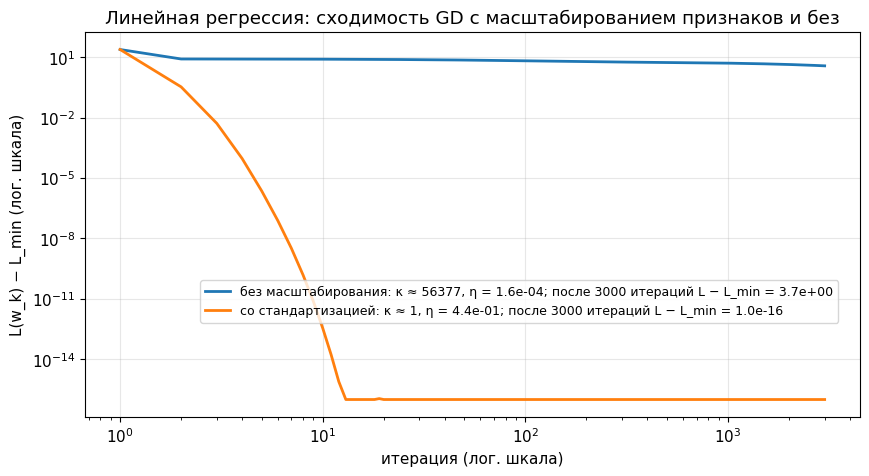

In [20]:
plt.figure(figsize=(10, 5))
for name, Xm in [("без масштабирования", Xb_raw), ("со стандартизацией", Xb_std)]:
    H = (2 / n) * Xm.T @ Xm
    lam, V = np.linalg.eigh(H)                        # собственные числа (по возрастанию) и векторы гессиана
    kappa, eta = lam.max() / lam.min(), 1 / lam.max()
    w, losses = gd_linreg(Xm, y_lin, eta=eta, n_iter=3000, eps=0)
    L_min = mse_loss(Xm, y_lin, normal_equation(Xm, y_lin))
    gap = np.maximum(losses - L_min, 1e-16)
    plt.loglog(np.arange(1, len(gap) + 1), gap, lw=2,
               label=f"{name}: κ ≈ {kappa:.0f}, η = {eta:.1e}; после 3000 итераций L − L_min = {gap[-1]:.1e}")
    print(f"{name:>22}: λ_min = {lam.min():.4f}, λ_max = {lam.max():.1f}, κ = {kappa:.2f}, η = {eta:.2e}")
    print(f"{'':>22}  собственный вектор для λ_min (компоненты: b, w1, w2, w3): {np.round(V[:, 0], 3)}")
plt.title("Линейная регрессия: сходимость GD с масштабированием признаков и без")
plt.xlabel("итерация (лог. шкала)"); plt.ylabel("L(w_k) − L_min (лог. шкала)")
plt.legend(loc="center right", bbox_to_anchor=(0.98, 0.3), fontsize=9)   # ниже центра: там кривые не проходят
plt.show()

**Что мы видим на графике.** Со стандартизацией кривая потерь обрывается вниз и упирается в машинную точность ($10^{-16}$) за полтора десятка итераций. Без масштабирования число обусловленности — десятки тысяч, шаг вынужденно крошечный (иначе расходимость вдоль направления «большого» признака с масштабом 100), и за 3000 итераций метод сократил разрыв с минимумом лишь в несколько раз — даже не на порядок: он застрял в овраге и медленно ползёт вдоль самого пологого направления. Это направление, как показывает напечатанный выше собственный вектор для $\lambda_{\min}$, — почти целиком комбинация свободного члена и признака с масштабом $\sim 1$ (компоненты при $w_2$ и $w_3$ близки к нулю): их «не видно» на фоне большого признака. Разница в скорости — многие порядки, и это без изменения алгоритма, только за счёт замены координат.

Практическое замечание: параметры стандартизации $\mu$ и $\sigma$ — часть модели. В реальном пайплайне их считают по обучающей выборке и применяют к тестовой (`scaler.fit(X_train)`, затем `scaler.transform(X_test)`), иначе информация о тесте «протекает» в обучение, а предсказания на новых данных окажутся в другой шкале.

## 6. Практика: логистическая регрессия  <span style="color:gray">⏱ ≈ 10 мин</span>

### 6.1 Модель, log-loss и вывод градиента

Логистическая регрессия — модель бинарной классификации: метки $y_i \in \{0, 1\}$, а модель предсказывает вероятность класса 1:
$$p_i = \sigma(\mathbf{x}_i^{\top}\mathbf{w}) = \frac{1}{1 + e^{-\mathbf{x}_i^{\top}\mathbf{w}}},\qquad \mathbf{p} = \sigma(X\mathbf{w})\ \text{(поэлементно)}.$$
Здесь, как и раньше, первый столбец $X$ — единицы, $w_0$ — свободный член. Функция потерь — log-loss (бинарная кросс-энтропия), с которой мы познакомились на занятии 1:
$$L(\mathbf{w}) = -\frac{1}{n}\sum_{i=1}^n \Bigl[ y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\Bigr].$$
На занятии 8 мы выведем её из принципа максимального правдоподобия; сегодня она для нас просто функция $d+1$ переменных, которую нужно минимизировать. Нормального уравнения здесь нет: $\mathbf{w}$ сидит внутри нелинейной $\sigma$, и уравнение $\nabla L = 0$ аналитически не решается. Остаётся градиентный спуск.

> **Утверждение.** Градиент log-loss логистической регрессии:
> $$\nabla L(\mathbf{w}) = \frac{1}{n} X^{\top}\bigl(\sigma(X\mathbf{w}) - \mathbf{y}\bigr).$$
>
> *Вывод.* Обозначим $z_i = \mathbf{x}_i^\top \mathbf{w}$ (логит), так что $p_i = \sigma(z_i)$ и $\nabla_{\mathbf{w}} z_i = \mathbf{x}_i$. Цепочка зависимостей: $\mathbf{w} \to z_i \to p_i \to L$. Считаем производные по звеньям:
> $$\frac{\partial L}{\partial p_i} = -\frac{1}{n}\left(\frac{y_i}{p_i} - \frac{1 - y_i}{1 - p_i}\right),\qquad \frac{d p_i}{d z_i} = \sigma'(z_i) = p_i(1 - p_i)\ \ (\text{занятие 2}).$$
> Перемножаем и раскрываем скобки:
> $$\frac{\partial L}{\partial z_i} = -\frac{1}{n}\left(\frac{y_i}{p_i} - \frac{1 - y_i}{1 - p_i}\right) p_i (1 - p_i) = -\frac{1}{n}\bigl(y_i(1 - p_i) - (1 - y_i)\,p_i\bigr) = -\frac{1}{n}(y_i - p_i) = \frac{1}{n}(p_i - y_i).$$
> Наконец, по цепному правилу $\nabla_{\mathbf{w}} L = \sum_i \dfrac{\partial L}{\partial z_i}\nabla_{\mathbf{w}} z_i = \dfrac1n\sum_i (p_i - y_i)\,\mathbf{x}_i = \dfrac1n X^\top(\mathbf{p} - \mathbf{y})$. $\blacksquare$

Сравните с градиентом MSE: $\frac{2}{n}X^\top(X\mathbf{w} - \mathbf{y})$. Структура одинаковая — «признаки, взвешенные ошибкой предсказания»; отличие лишь в том, что предсказание проходит через сигмоиду, а множителя 2 нет — в MSE он появлялся от дифференцирования квадрата, а в log-loss квадрата нет. Это не совпадение: на занятии 8 мы увидим, что обе функции потерь — минус-логарифм правдоподобия, и у всех потерь такого рода градиент имеет вид «$X^\top(\text{предсказание} - \text{ответ})$».

> 💡 **ML-контекст.** Логистическая регрессия — это один нейрон с сигмоидной активацией, а только что выведенная формула — backpropagation через один слой: «ошибка» $\boldsymbol\delta = \mathbf{p} - \mathbf{y}$ на выходе, градиент по весам — входы, умноженные на ошибку, ровно как в примере двухслойной сети из блока 3. Обратите внимание, как аккуратно сократились $p_i(1 - p_i)$ из производной сигмоиды и знаменатели из производной логарифма: именно поэтому в PyTorch есть `BCEWithLogitsLoss`, которая считает сигмоиду и log-loss вместе — численно устойчивее и без лишних операций.

> ⚠️ **Типичная ошибка.** Вычислять $\ln p_i$ или $\ln(1 - p_i)$ при $p_i$, численно равном 1 или 0 (в `float64` сигмоида округляется ровно до `1.0` уже при $z \gtrsim 37$ — мы видели это на занятии 1, — а до `0.0` при $z \lesssim -709$, когда переполняется $e^{-z}$): получаем `-inf` и `nan` в значении потерь. Стандартная защита — обрезать вероятности: `np.clip(p, 1e-15, 1 - 1e-15)` перед логарифмом. На вычисление градиента это не влияет — в формуле $\frac1n X^\top(\mathbf p - \mathbf y)$ логарифмов нет.

Сгенерируем два пересекающихся облака точек (`make_blobs`), обучим логистическую регрессию градиентным спуском и сравним с `sklearn.linear_model.LogisticRegression` (с практически отключённой регуляризацией, чтобы задачи совпадали).

In [21]:
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression

X_bl, y_bl = make_blobs(n_samples=200, centers=[[-2, -1], [2, 1]], cluster_std=1.7, random_state=42)
Xb_bl = add_bias(X_bl)                                   # столбец единиц + два признака

def sigmoid(z):
    """Сигмоида σ(z) = 1 / (1 + e^(−z))."""
    return 1 / (1 + np.exp(-z))

def log_loss(X, y, w):
    """Log-loss = −(1/n) Σ [y ln p + (1 − y) ln(1 − p)], p = σ(Xw); вероятности обрезаны для устойчивости."""
    p = np.clip(sigmoid(X @ w), 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def log_loss_grad(X, y, w):
    """Градиент log-loss: (1/n)·Xᵀ(σ(Xw) − y)."""
    return X.T @ (sigmoid(X @ w) - y) / len(y)

def gd_logreg(X, y, eta, n_iter=5000, eps=1e-8):
    """Логистическая регрессия градиентным спуском из w = 0; возвращает веса и историю потерь."""
    w = np.zeros(X.shape[1])
    losses = []
    for k in range(n_iter):
        losses.append(log_loss(X, y, w))
        g = log_loss_grad(X, y, w)
        if np.linalg.norm(g) < eps:
            break
        w = w - eta * g
    return w, np.array(losses)

w_log, losses_log = gd_logreg(Xb_bl, y_bl, eta=0.5)
acc_gd = np.mean((sigmoid(Xb_bl @ w_log) > 0.5) == y_bl)
print(f"GD: {len(losses_log)} итераций, log-loss = {losses_log[-1]:.6f}, ‖∇L‖ = {np.linalg.norm(log_loss_grad(Xb_bl, y_bl, w_log)):.1e}, accuracy = {acc_gd:.3f}")

sk_log = LogisticRegression(C=1e10, max_iter=10000).fit(X_bl, y_bl)   # огромное C ≈ без регуляризации
w_sk_log = np.concatenate([sk_log.intercept_, sk_log.coef_[0]])
display(pd.DataFrame({"GD с нуля": w_log, "sklearn": w_sk_log}, index=["b (w0)", "w1", "w2"]).round(5))
print(f"sklearn: log-loss = {log_loss(Xb_bl, y_bl, w_sk_log):.6f}, accuracy = {sk_log.score(X_bl, y_bl):.3f}")

GD: 529 итераций, log-loss = 0.175907, ‖∇L‖ = 1.0e-08, accuracy = 0.935


,GD с нуля,sklearn
b (w0),0.00568,0.00546
w1,1.58916,1.58892
w2,0.65964,0.65995


sklearn: log-loss = 0.175907, accuracy = 0.935


Веса, найденные нашим градиентным спуском, совпали с `sklearn` с точностью около $3 \cdot 10^{-4}$ (остаток — допуск решателя `sklearn`, который использует более быстрый квазиньютоновский метод L-BFGS, о нём на занятии 6), а значения log-loss и доли правильных ответов совпали полностью: к одному и тому же минимуму ведут разные дороги. Нарисуем результат: точки двух классов, вероятность класса 1 цветом и *границу решения* — множество точек, где $p = 0.5$, то есть $\mathbf{x}^\top\mathbf{w} = 0$, или $w_0 + w_1 x_1 + w_2 x_2 = 0$: это прямая $x_2 = -(w_0 + w_1 x_1)/w_2$. Рядом — кривая потерь по итерациям.

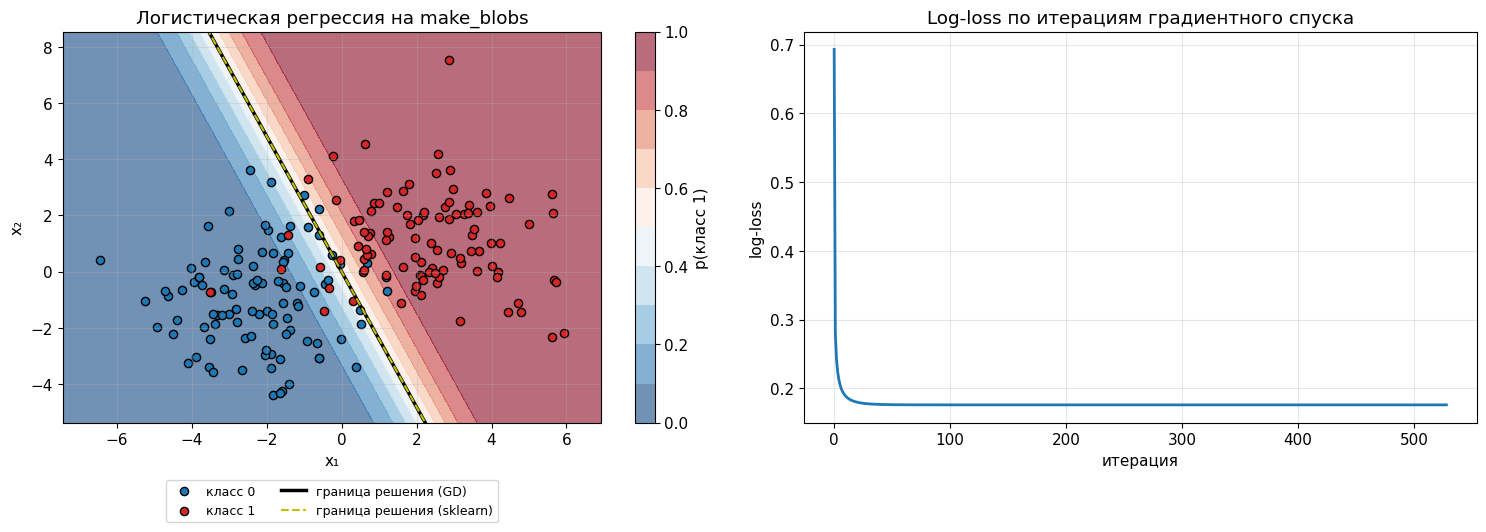

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Слева: данные, вероятности класса 1 и граница решения
ax = axes[0]
x1s = np.linspace(X_bl[:, 0].min() - 1, X_bl[:, 0].max() + 1, 200)
x2s = np.linspace(X_bl[:, 1].min() - 1, X_bl[:, 1].max() + 1, 200)
G1, G2 = np.meshgrid(x1s, x2s)
P = sigmoid(w_log[0] + w_log[1] * G1 + w_log[2] * G2)            # вероятность класса 1 на сетке
cf = ax.contourf(G1, G2, P, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
plt.colorbar(cf, ax=ax, label="p(класс 1)")
ax.scatter(X_bl[y_bl == 0, 0], X_bl[y_bl == 0, 1], c="tab:blue", edgecolor="k", s=35, label="класс 0")
ax.scatter(X_bl[y_bl == 1, 0], X_bl[y_bl == 1, 1], c="tab:red", edgecolor="k", s=35, label="класс 1")
ax.plot(x1s, -(w_log[0] + w_log[1] * x1s) / w_log[2], "k-", lw=2.5, label="граница решения (GD)")
ax.plot(x1s, -(w_sk_log[0] + w_sk_log[1] * x1s) / w_sk_log[2], "y--", lw=1.5, label="граница решения (sklearn)")
ax.set_xlim(x1s.min(), x1s.max()); ax.set_ylim(x2s.min(), x2s.max())
ax.set_title("Логистическая регрессия на make_blobs"); ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=9)   # легенда под графиком: не закрывает ни точки, ни границу

# Справа: кривая потерь
ax = axes[1]
ax.plot(losses_log, lw=2)
ax.set_title("Log-loss по итерациям градиентного спуска"); ax.set_xlabel("итерация"); ax.set_ylabel("log-loss")
plt.tight_layout(); plt.show()

**Что мы видим на графике.** Граница решения — прямая, разделяющая облака; границы от нашего GD и от `sklearn` совпадают. Цвет фона показывает уверенность модели: вблизи границы вероятность около $0.5$, вдали — близка к 0 или 1. Кривая потерь убывает монотонно и без зигзагов: признаки `make_blobs` уже примерно одного масштаба, а поверхность log-loss, как мы докажем на занятии 4, выпуклая — у неё один минимум, и GD его находит.

> ❓ **Вопрос аудитории.** Почему граница решения логистической регрессии — прямая (а в $\mathbb{R}^d$ — гиперплоскость), хотя модель нелинейная из-за сигмоиды?
>
> <details><summary>Ответ</summary>
>
> Граница — это множество точек, где $p = \sigma(\mathbf{x}^\top\mathbf{w}) = 0.5$. Сигмоида монотонна и равна $0.5$ ровно при нулевом аргументе, поэтому условие равносильно $\mathbf{x}^\top\mathbf{w} = 0$ — линейному уравнению относительно $\mathbf{x}$. Нелинейность сигмоиды влияет на *уверенность* (как быстро вероятность отходит от $0.5$ при удалении от границы — это регулирует $\|\mathbf{w}\|$), но не на форму границы. Чтобы получить кривую границу, нужно добавить нелинейные признаки ($x_1^2$, $x_1 x_2$, …) или использовать нейросеть — композицию таких моделей, как в примере с backprop.
>
> </details>

## Итоги занятия

Что мы сегодня узнали:

1. Функция потерь — функция от *всех* параметров модели сразу; её график — поверхность («ландшафт»), а самое удобное представление — линии уровня. MSE линейной регрессии — эллиптический параболоид, и вытянутость его линий уровня уже предвещает проблемы оптимизации.
2. Частная производная — производная по одной переменной при замороженных остальных; считается обычными правилами, проверяется в sympy и численно; геометрически — наклон сечения поверхности. Смешанные производные не зависят от порядка дифференцирования (теорема Шварца), поэтому гессиан симметричен.
3. Градиент — вектор частных производных. Он задаёт линейное приближение $f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \langle \nabla f, \mathbf{h}\rangle$ и через него выражается производная по любому направлению: $D_{\mathbf u} f = \langle\nabla f, \mathbf u\rangle = \|\nabla f\|\cos\varphi$.
4. Градиент — направление наискорейшего роста, антиградиент — наискорейшего убывания, оба ортогональны линиям уровня. Это доказывается одной строкой через косинус угла.
5. Матрица Якоби обобщает градиент на векторные функции, а цепное правило $J_{G\circ F} = J_G\, J_F$ — это математика backpropagation: мы реализовали его руками для двухслойной сети и сверили с `torch.autograd`.
6. Градиентный спуск $\mathbf{x}_{k+1} = \mathbf{x}_k - \eta\nabla f(\mathbf{x}_k)$: допустимый шаг ограничен самым крутым направлением ($\eta < 2/\lambda_{\max}$), а скорость сходимости диктует самое пологое; число итераций растёт линейно по числу обусловленности $\kappa = \lambda_{\max}/\lambda_{\min}$. Овраги — причина зигзагов, масштабирование признаков — лекарство.
7. Градиент MSE: $\frac2n X^\top(X\mathbf{w} - \mathbf{y})$; градиент log-loss: $\frac1n X^\top(\sigma(X\mathbf{w}) - \mathbf{y})$. Реализованный с нуля GD для обеих моделей совпал с эталонами — нормальным уравнением и `sklearn`.

На следующем занятии мы ответим на вопрос, который сегодня обходили стороной: как убедиться, что точка с нулевым градиентом — действительно минимум, а не седло или максимум? Для этого понадобятся гессиан, критерий Сильвестра и понятие выпуклости; мы докажем, что MSE и log-loss выпуклы по параметрам, а затем научимся оптимизировать с ограничениями — методом множителей Лагранжа, из которого вырастают Ridge-регрессия и PCA. А в модуле 3 вернёмся к градиентному спуску и разберём, как бороться с оврагами умнее, чем масштабированием: momentum, Adam, расписания шага и метод Ньютона.